# Data Collection and Preparation SIS 1 - Manga Sales vs Critical Reception

> by Nursultan Zhantuar

## Setup

In [1]:
import os
import re
import time
import json
import difflib
import unicodedata
from urllib import robotparser

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import requests
from bs4 import BeautifulSoup

import warnings
warnings.filterwarnings("ignore")

In [2]:
%pip freeze > requirements.txt

In [3]:
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
sns.set_theme(style="whitegrid", context="notebook")

HEADERS = {"User-Agent": "manga-sales-vs-ratings-student-project/1.0 (educational use)"}

os.makedirs("data", exist_ok=True)

## Task 1: Project topic, data sources and hypotheses

The area I decided to use is **manga** - comic books from Japan. The goal of the project is to find out whether the commercial success of a manga series (how many copies it sold) correlates together with how well it is received by readers / fans, and whether the publisher and the genre/demographic of a series play a significant role in both.

### API
I used the **Jikan API** (https://docs.api.jikan.moe/), an open unofficial REST API for MyAnimeList (MAL).

> **Important** - there was a global outage of the API during the time I started working on this project, so I had to use a backup version with slightly functionality (the one I used below). The API is called Jikan Edge: https://github.com/LucasHenriqueDiniz/jikan-edge

Two endpoints were used:
- GET `/v4/top/manga` - paginated list of manga (25 per page). I sort it by popularity so that the sample is not biased towards only the highest-scored titles.
  - Due to outage replaced with `v1/manga` sorted by the number of members on MAL (same as popularity). From Jikan Edge API
- GET `/v4/manga?q=<title>` - search endpoint, used to find MAL records for series from the Wikipedia table that are not in the popularity list.
  - Due to outage replaced with `v1/manga?q=title` Frin Jikan Edge API
Jikan has a rate limit (3 requests per second and 60 per minute), so every request is followed by a pause of about one second.

### Static web page
For the static page I used the Wikipedia article about the best-selling manga series, since it contains several structured tables with the sales numbers, publisher, demographic and number of volumes of every series.
https://en.wikipedia.org/wiki/List_of_best-selling_manga

### Hypotheses
- **H1**: Manga sales are positively correlated with the critical perception of the manga (MAL score, number of voters, members and favorites).
- **H2**: The publisher and the demographic/genre of a manga explain a significant share of the variation in sales and popularity.

A note on terminology: MAL score is an average of **user** ratings, not of professional critics, so I treat it as a proxy for the "critical perception" by the readers, not any professional opinions.

## Task 2: API Data Collection

### Requesting data from the selected API

First, I wrote a small helper that sends a request, retries when the API answers with `429 Too Many Requests` or a server error, and returns the JSON. Then I requested the first page of the popularity list, checked the response status and examined the returned JSON.


> Important - there was a global outage of the API during the time I started working on this project, so I had to use a backup version with slightly functionality (the one I used below)

In [4]:
JIKAN_BASE = "https://jikan.lucashdo.com/v1"

def fetch_json(url, params=None, retries=5, pause=1.1):
    """
    GET request with retries for rate limiting (429) and server errors (5xx)
    """
    for attempt in range(retries):
        r = requests.get(url, params=params, timeout=30, headers=HEADERS, verify=False)
        if r.status_code == 429 or r.status_code >= 500:
            if r.status_code == 502:
                return None
            time.sleep(pause * (attempt + 2))
            continue
        r.raise_for_status()
        return r.json()
    raise RuntimeError(f"Request failed after {retries} attempts: {url}")

In [5]:
resp = requests.get(
    f"{JIKAN_BASE}/manga",
    timeout=30,
    params={"type": "manga", "order_by": "members","page": 1},
    verify=False,
    headers=HEADERS
)
resp.raise_for_status()

{"status_code": resp.status_code, "content_type": resp.headers.get("Content-Type")}

{'status_code': 200, 'content_type': 'application/json'}

In [6]:
payload = resp.json()
list(payload.keys())

['data', 'meta']

In [7]:
payload["meta"]

{'cached': False,
 'stale': False,
 'refreshFailed': False,
 'fetchedAt': '2026-10-29T04:44:33.301Z',
 'pagination': {'page': 1,
  'limit': 50,
  'count': 50,
  'total': None,
  'hasNextPage': True}}

The response has two top-level keys - `meta` and `data`. `data` is an array of manga records and it is the main target of the analysis, while `pagination` tells me how many pages exist and whether there is a next one. Let's look at the structure of a single record.

In [8]:
payload["data"][0]

{'malId': 2,
 'url': 'https://myanimelist.net/manga/2/Berserk',
 'title': 'Berserk',
 'imageUrl': 'https://cdn.myanimelist.net/images/manga/1/157897.jpg',
 'synopsis': 'Guts, a former mercenary now known as the Black Swordsman, is out for revenge. After a tumultuous childhood, he finally finds someone he respects and believes he can trust, only to have everything fal',
 'type': 'Manga',
 'score': 9.46,
 'startDate': '1989-08-25',
 'endDate': None,
 'members': 813255,
 'volumes': None,
 'chapters': None}

We can see fields like title, id, synopsis, user score, number of members, volumes and chapters. Since 'Berserk' is an ongoing mange it has None for the number of volumes and chapters

### Collecting the dataset from API

The root manga endpoint does not return much information, so I would start by fetching the identifiers of manga titles, and then getting information for each of them separately.

I start by fetching 1000 manga titles and writing them to a JSON file to avoid re-fetching the list. Since 1 request returns 50 results, I made 20 paginated requests

In [9]:
NUM_PAGES = 20
TOP_PARAMS = {"type": "manga", "order_by": "members"}
TOP_CACHE = "data/jikan_top_manga_raw.json"

IS_TOP_CACHED = os.path.exists(TOP_CACHE)

if IS_TOP_CACHED:
    with open(TOP_CACHE, "r", encoding="utf-8") as f:
        top_raw = json.load(f)
else:
    top_raw = []
    for page in range(1, NUM_PAGES + 1):
        payload = fetch_json(f"{JIKAN_BASE}/manga", params={**TOP_PARAMS, "page": page})
        top_raw.extend(payload["data"])
        if page % 10 == 0:
            print(f"Page {page} completed, {len(top_raw)} records so far")
        if not payload["meta"]["pagination"]["hasNextPage"]:
            break
        time.sleep(1.1)

    with open(TOP_CACHE, "w", encoding="utf-8") as f:
        json.dump(top_raw, f, ensure_ascii=False)

{"loaded_from_cache": IS_TOP_CACHED, "records": len(top_raw)}

Page 10 completed, 500 records so far
Page 20 completed, 1000 records so far


{'loaded_from_cache': False, 'records': 1000}

The raw records were saved as a proper JSON file (with `json.dump`), so that they can be loaded again with `json.load`.

### Colleting Detailed Dataset from API

In [10]:
DETAILED_CACHE = "data/jikan_detailed_manga_raw.json"

IS_CACHED = os.path.exists(DETAILED_CACHE)

if IS_CACHED:
    with open(DETAILED_CACHE, "r", encoding="utf-8") as f:
        raw = json.load(f)
else:
    raw = []
    id_list = [manga["malId"] for manga in top_raw]
    print("Total manga records:", len(id_list))

    for mal_id in id_list:
        payload = fetch_json(f"{JIKAN_BASE}/manga/{mal_id}")
        if payload is None:
            print("Skipping manga with id:", mal_id)
            continue
        raw.append(payload["data"])
        if len(raw) % 10 == 0:
            print(f"{len(raw)} detailed manga records so far")
        time.sleep(1.1)

    with open(DETAILED_CACHE, "w", encoding="utf-8") as f:
        json.dump(raw, f, ensure_ascii=False)

{"loaded_from_cache": IS_CACHED, "records": len(raw)}

{'loaded_from_cache': True, 'records': 995}

## Task 3: JSON Processing

### Flattening the JSON dataset

Let's start by flattening the nested records with `pd.json_normalize`. Nested dictionaries (like `published`) become dotted columns, while lists of dictionaries stay as they are.

In [11]:
raw_df = pd.json_normalize(raw)
raw_df.shape

(995, 34)

In [12]:
raw_df.columns.tolist()

['malId',
 'url',
 'title',
 'titleEnglish',
 'titleJapanese',
 'titleSynonyms',
 'imageUrl',
 'synopsis',
 'background',
 'type',
 'volumes',
 'chapters',
 'status',
 'publishing',
 'authors',
 'serializations',
 'genres',
 'themes',
 'demographics',
 'score',
 'scoredBy',
 'rank',
 'popularity',
 'members',
 'favorites',
 'relations',
 'externalLinks',
 'fetchedAt',
 'images.small',
 'images.medium',
 'images.large',
 'published.from',
 'published.to',
 'published.string']

There are many columns that are not needed for this project (image URLs, synopsis). I will keep only the fields related to the sales/reception analysis: identifiers, titles, type, volumes/chapters, the reception metrics (score, members, rank), the publishing date and the lists of genres, authors, magazines and demographics. The lists of gengres, authors, magazines, etc. have to be exploded / parsed separately to be used in analysis

There is also an important difference in Jikan API and Jikan Edge API - all columns in the Edge API have camelCase names. In order to keep everything more pythonic, I will rename them all to snake_case

### Extracting values from the nested lists

The lists of dictionaries need to be converted into usable columns. I wrote small helpers:
- `names()` takes all the `name` values from a list, and `first_name()` takes only the first one (e.g. the first magazine is treated as the main serialization).
- Demographic labels differ between sources ("Shounen" in MAL, "Shōnen" in Wikipedia), so I also wrote a function that maps them to one standard English spelling.

In [13]:
def names(lst):
    return [d["name"] for d in lst] if isinstance(lst, list) else []

def first_name(lst):
    return lst[0]["name"] if isinstance(lst, list) and len(lst) > 0 else np.nan

def norm_demo(s):
    """
    Standardise demographic labels from both sources (Shounen/Shōnen -> Shonen, etc.)
    """
    if pd.isna(s):
        return np.nan
    t = s.lower().replace("ō", "o").replace("ū", "u").replace("ou", "o")
    for key in ["shonen", "seinen", "shojo", "josei"]:
        if key in t:
            return key.capitalize()
    if "kids" in t or "kodomo" in t:
        return "Kodomo"
    return "Other"

def all_titles_of(rec):
    """Return list of all title - official English title and alt titles"""
    out = [rec.get("title"), rec.get("titleEnglish")]
    out += rec.get("titleSynonyms", []) or []
    return [t for t in dict.fromkeys(out) if t]

def to_frame(records):
    df = pd.json_normalize(records)
    keep = ["malId", "title", "titleEnglish", "type", "chapters", "volumes", "status", "publishing",
            "score", "scoredBy", "rank", "popularity", "members", "favorites", "published.from",
            "authors", "serializations", "genres", "themes", "demographics"]
    df = df[[c for c in keep if c in df.columns]].rename(
        columns={
            "published.from": "published_from",
            "malId": "mal_id",
            "title": "title",
            "titleEnglish": "title_english",
            "type": "type",
            "chapters": "chapters",
            "volumes": "volumes",
            "publishing": "publishing",
            "score": "score",
            "scoredBy": "scored_by",
            "rank": "rank",
            "popularity": "popularity",
            "members": "members",
            "favorites": "favorites",
            "authors": "authors",
            "serializations": "serializations",
            "genres": "genres",
            "themes": "themes",
            "demographics": "demographics"
        }
    )

    df["all_titles"] = [all_titles_of(r) for r in records]
    df["genre_list"] = df["genres"].apply(names)
    df["theme_list"] = df["themes"].apply(names)
    df["primary_genre"] = df["genre_list"].apply(lambda g: g[0] if g else np.nan)
    df["demographic"] = df["demographics"].apply(first_name).map(norm_demo)
    df["magazine"] = df["serializations"].apply(first_name)
    df["author"] = df["authors"].apply(first_name)
    df["start_year"] = pd.to_datetime(df["published_from"], errors="coerce", utc=True).dt.year

    return df.drop(columns=["genres", "themes", "demographics", "authors", "serializations", "published_from"])

df_tmp = to_frame(raw)
df_tmp.head()

,mal_id,title,title_english,type,chapters,volumes,status,publishing,score,scored_by,rank,popularity,members,favorites,all_titles,genre_list,theme_list,primary_genre,demographic,magazine,author,start_year
0,2,Berserk,Berserk,Manga,NaN,NaN,Publishing,True,9.46,406793,1.0,1,813179,139874,"[Berserk, Berserk: The Prototype]","[Action, Adventure, Award Winning, Drama, Fantasy, Horror]","[Gore, Military, Psychological]",Action,Seinen,Young Animal,"Miura, Kentarou",1989.0
1,116778,Chainsaw Man,Chainsaw Man,Manga,232.0,24.0,Finished,False,8.61,458399,108.0,2,750865,92580,[Chainsaw Man],"[Action, Award Winning, Fantasy]","[Gore, Urban Fantasy]",Action,Shonen,Shounen Jump+,"Fujimoto, Tatsuki",2018.0
2,13,One Piece,One Piece,Manga,NaN,NaN,Publishing,True,9.20,427636,4.0,3,710237,127219,[One Piece],"[Action, Adventure, Fantasy]",[],Action,Shonen,Shounen Jump (Weekly),"Oda, Eiichiro",1997.0
3,23390,Shingeki no Kyojin,Attack on Titan,Manga,141.0,34.0,Finished,False,8.56,434694,135.0,4,699821,70072,"[Shingeki no Kyojin, Attack on Titan]","[Action, Award Winning, Drama, Suspense]","[Gore, Military, Survival]",Action,Shonen,Bessatsu Shounen Magazine,"Isayama, Hajime",2009.0
4,33327,Tokyo Ghoul,Tokyo Ghoul,Manga,144.0,14.0,Finished,False,8.56,316840,136.0,6,580422,52253,"[Tokyo Ghoul, Toukyou Kushu]","[Action, Fantasy, Horror]","[Gore, Psychological, Urban Fantasy]",Action,Seinen,Young Jump,"Ishida, Sui",2011.0


Now every record has simple columns (`demographic`, `magazine`, `author`, `start_year`, `primary_genre`) and two list columns (`genre_list`, `theme_list`) which keep **all** genres and themes of a manga. The list columns are what makes `explode` useful later: one row per manga-genre pair. This sort of dataframe can be used to analyze the distribution of genres across manga titles



In [14]:
df_tmp[["title", "genre_list"]].explode("genre_list").head(8)

,title,genre_list
0,Berserk,Action
0,Berserk,Adventure
0,Berserk,Award Winning
0,Berserk,Drama
0,Berserk,Fantasy
0,Berserk,Horror
1,Chainsaw Man,Action
1,Chainsaw Man,Award Winning


### Imputing missing values, fixing data types and deduplication

Next, I will turn empty strings into `NaN`, check the missing values and convert the data types: identifiers and counters to nullable integers (`Int64`), categorical columns to `category`.

In [15]:
def clean_api(df):
    df = df.copy()
    str_cols = ["title", "title_english", "magazine", "author"]
    df[str_cols] = df[str_cols].replace(r"^\s*$", np.nan, regex=True)

    int_cols = ["mal_id", "chapters", "volumes", "scored_by", "rank", "popularity", "members", "favorites"]
    for col in int_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce").astype("Int64")
    df["score"] = pd.to_numeric(df["score"], errors="coerce")
    df["start_year"] = df["start_year"].astype("Int64")

    for col in ["type", "status", "demographic"]:
        df[col] = df[col].astype("category")

    return df

df_clean = clean_api(df_tmp)
df_clean.isna().sum()

,0
mal_id,0
title,0
title_english,131
type,0
chapters,236
volumes,231
status,0
publishing,0
score,0
scored_by,0


The most important thing to note is the amount of missing values in `score`, `demographic` and `magazine`. A missing score means the series has not been rated by enough users, and those series have to be left out of any correlation analysis. A missing demographic is simply not filled in for some series in MAL.

In [16]:
df_clean.dtypes

,0
mal_id,Int64
title,object
title_english,object
type,category
chapters,Int64
volumes,Int64
status,category
publishing,bool
score,float64
scored_by,Int64


Since pagination of a live list can shift between requests (a manga may move to another page while I am downloading, which is pretty unlikely, but still possible), the same series may appear twice, so I deduplicate by the MAL identifier.

In [17]:
print("Duplicate rows (by mal_id):", df_clean.duplicated(subset="mal_id").sum())
df_top = df_clean.drop_duplicates(subset="mal_id").reset_index(drop=True)
df_top.shape

Duplicate rows (by mal_id): 0


(995, 22)

In [18]:
df_top.head()

,mal_id,title,title_english,type,chapters,volumes,status,publishing,score,scored_by,rank,popularity,members,favorites,all_titles,genre_list,theme_list,primary_genre,demographic,magazine,author,start_year
0,2,Berserk,Berserk,Manga,<NA>,<NA>,Publishing,True,9.46,406793,1,1,813179,139874,"[Berserk, Berserk: The Prototype]","[Action, Adventure, Award Winning, Drama, Fantasy, Horror]","[Gore, Military, Psychological]",Action,Seinen,Young Animal,"Miura, Kentarou",1989
1,116778,Chainsaw Man,Chainsaw Man,Manga,232,24,Finished,False,8.61,458399,108,2,750865,92580,[Chainsaw Man],"[Action, Award Winning, Fantasy]","[Gore, Urban Fantasy]",Action,Shonen,Shounen Jump+,"Fujimoto, Tatsuki",2018
2,13,One Piece,One Piece,Manga,<NA>,<NA>,Publishing,True,9.20,427636,4,3,710237,127219,[One Piece],"[Action, Adventure, Fantasy]",[],Action,Shonen,Shounen Jump (Weekly),"Oda, Eiichiro",1997
3,23390,Shingeki no Kyojin,Attack on Titan,Manga,141,34,Finished,False,8.56,434694,135,4,699821,70072,"[Shingeki no Kyojin, Attack on Titan]","[Action, Award Winning, Drama, Suspense]","[Gore, Military, Survival]",Action,Shonen,Bessatsu Shounen Magazine,"Isayama, Hajime",2009
4,33327,Tokyo Ghoul,Tokyo Ghoul,Manga,144,14,Finished,False,8.56,316840,136,6,580422,52253,"[Tokyo Ghoul, Toukyou Kushu]","[Action, Fantasy, Horror]","[Gore, Psychological, Urban Fantasy]",Action,Seinen,Young Jump,"Ishida, Sui",2011


## Task 4: Web Scraping

### Checking robots.txt, downloading the page and finding the tables

I requested the page with the requests library and used Beautiful Soup to find all the tables of the wikitable class.

In [19]:
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_best-selling_manga"

False

In [20]:
page = requests.get(WIKI_URL, headers=HEADERS, timeout=30)
page.raise_for_status()

soup = BeautifulSoup(page.text, "html.parser")
tables = soup.find_all("table", class_="wikitable")

print("Status Code", page.status_code)
print("Number of tables", len(tables))

Status Code 200
Number of tables 4


### Writing a table parser

Wikipedia tables are not trivial to parse: cells contain footnote markers (`[a]`), line breaks between several values, and rowspan cells (for example, a publisher name written once for several consecutive series). A simple "one `<td>` = one column" loop would shift the columns in such rows.

Therefore I wrote a parser that:
- removes footnotes (`<sup>`) and style tags from the cell text,
- replaces `<br>` with a separator,
- remembers cells with rowspan/colspan and repeats their value in the following rows.

In [22]:
def clean_text(text):
    text = re.sub(r"\[[^\]]*\]", "", text) # removing foot notes
    text = re.sub(r"†", "", text) # dunno what these mean
    text = re.sub(r"‡", "", text)
    return re.sub(r"\s+", " ", text).strip() # removing spaces


def cell_text(cell):
    for tag in cell.find_all(["sup", "style"]):
        tag.decompose()
    for br in cell.find_all("br"):
        br.replace_with(" | ")
    return clean_text(cell.get_text(" ", strip=True))


def parse_table(table):
    """
    Returns the table as a list of rows (list of strings), expanding rowspan/colspan
    """
    rows, spans = [], {}
    for tr in table.find_all("tr"):
        cells = tr.find_all(["th", "td"], recursive=False)
        row, col, ci = [], 0, 0
        while ci < len(cells) or col in spans:
            if col in spans:
                text, left = spans[col]
                row.append(text)
                if left > 1:
                    spans[col] = (text, left - 1)
                else:
                    del spans[col]
                col += 1
                continue
            cell = cells[ci]
            ci += 1
            text = cell_text(cell)
            rs = int(re.sub(r"\D", "", cell.get("rowspan", "1")) or 1)
            cs = int(re.sub(r"\D", "", cell.get("colspan", "1")) or 1)
            for _ in range(cs):
                row.append(text)
                if rs > 1:
                    spans[col] = (text, rs - 1)
                col += 1
        if row:
            rows.append(row)
    return rows

[(i, parse_table(t)[0]) for i, t in enumerate(tables)]

[(0,
  ['Manga series',
   'Author(s)',
   'Publisher',
   'Demographic',
   'No. of collected | volumes',
   'Serialized',
   'Approximate sales']),
 (1,
  ['Manga series',
   'Author(s)',
   'Publisher',
   'Demographic',
   'No. of collected | volumes',
   'Serialized',
   'Approximate | sales']),
 (2,
  ['Manga series',
   'Author(s)',
   'Publisher',
   'Demographic',
   'No. of collected | volumes',
   'Serialized',
   'Approximate | sales']),
 (3,
  ['Manga series',
   'Author(s)',
   'Publisher',
   'Demographic',
   'No. of collected | volumes',
   'Serialized',
   'Approximate | sales'])]

Here I printed the header row of every table on the page. The tables that I need are the ones with a series column and a sales column. Their column names are not exactly the same everywhere, so the next step maps every header to a standard name by keywords (`series`, `author`, `publisher`, `demographic`, `volumes_raw`, `years_raw`, `sales_raw`). Every table also remembers the section heading it is under (for example, the sales bracket), which is saved as `wiki_section`.

In [23]:
def map_columns(headers):
    """Map the index of every header to a standard column name by keywords."""
    rules = [("sales_raw", ["sales", "copies"]), ("author", ["author", "creator"]),
             ("publisher", ["publisher"]), ("demographic", ["demograph"]),
             ("volumes_raw", ["volume"]), ("years_raw", ["serializ", "year", "period"]),
             ("series", ["series", "title", "manga"])]
    mapping, used = {}, set()
    for i, h in enumerate(headers):
        hl = h.lower()
        for key, words in rules:
            if key not in used and any(w in hl for w in words):
                mapping[i] = key
                used.add(key)
                break
    return mapping

def section_of(table):
    h = table.find_previous(["h2", "h3"])
    return clean_text(h.get_text(" ", strip=True)) if h else np.nan

records = []
for t in tables:
    parsed = parse_table(t)
    if len(parsed) < 2:
        continue
    headers = parsed[0]
    cmap = map_columns(headers)
    if not {"series", "sales_raw"} <= set(cmap.values()):
        continue
    section = section_of(t)
    for r in parsed[1:]:
        if len(r) != len(headers):
            continue
        rec = {cmap[i]: r[i] for i in cmap}
        rec["wiki_section"] = section
        records.append(rec)

df_wiki_raw = pd.DataFrame(records)
df_wiki_raw.shape

(201, 8)

In [24]:
df_wiki_raw.head(10)

,series,author,publisher,demographic,volumes_raw,years_raw,sales_raw,wiki_section
0,One Piece,Eiichiro Oda,Shueisha,Shōnen,115,1997–present,600 million,At least 100 million copies
1,Doraemon,Fujiko F. Fujio,Shogakukan,Children,45,1969–1996,300 million,At least 100 million copies
2,Golgo 13,"Takao Saito , Saito Production",Shogakukan,Seinen,221,1968–present,300 million,At least 100 million copies
3,Case Closed / Detective Conan,Gosho Aoyama,Shogakukan,Shōnen,108,1994–present,270 million,At least 100 million copies
4,Dragon Ball,Akira Toriyama,Shueisha,Shōnen,42,1984–1995,260 million,At least 100 million copies
5,Naruto,Masashi Kishimoto,Shueisha,Shōnen,72,1999–2014,250 million,At least 100 million copies
6,Demon Slayer: Kimetsu no Yaiba,Koyoharu Gotouge,Shueisha,Shōnen,23,2016–2020,220 million,At least 100 million copies
7,Slam Dunk,Takehiko Inoue,Shueisha,Shōnen,31,1990–1996,185 million,At least 100 million copies
8,KochiKame: Tokyo Beat Cops,Osamu Akimoto,Shueisha,Shōnen,201,1976–2016,157.2 million,At least 100 million copies
9,Jujutsu Kaisen,Gege Akutami,Shueisha,Shōnen,30,2018–2024,150 million,At least 100 million copies


At this point it is worth looking at the raw table before cleaning: the number of rows should match the number of series on the page, and the columns should be aligned (the publisher must really be a publisher, not a number of volumes). If the header of some table had two levels, its rows would be skipped by the `len(r) != len(headers)` check, which is why I check the shape first.

### Cleaning the scraped data

The raw table contains only text, so the numeric fields have to be parsed:
- `sales_m` - approximate sales converted to **millions of copies** (handles "million" and "billion" words and thousands separators),
- `volumes_wiki` - the first number in the volumes column,
- `start_year_wiki` - the first four-digit year of the serialization period,
- `publisher` - the main publisher: only the first publisher is kept, the parentheses are removed and several spellings are mapped to one name,
- `demographic` - standardized with the same `norm_demo` function as in the API data.

In [25]:
def parse_sales(s):
    """'516.6 million' -> 516.6, '1.2 billion' -> 1200.0 (millions of copies)."""
    if pd.isna(s):
        return np.nan
    m = re.search(r"(\d[\d,]*\.?\d*)", s)
    if not m:
        return np.nan
    val = float(m.group(1).replace(",", ""))
    low = s.lower()
    if "billion" in low:
        return val * 1000
    if "million" in low:
        return val
    return val / 1e6 if val > 10_000 else val

PUB_MAP = {
    "square enix": "Square Enix",
    "enix": "Square Enix",
    "kadokawa": "Kadokawa",
    "shueisha": "Shueisha",
    "kodansha": "Kodansha",
    "shogakukan": "Shogakukan",
    "akita": "Akita Shoten",
    "hakusensha": "Hakusensha",
    "futabasha": "Futabasha"
}

def primary_publisher(s):
    if pd.isna(s):
        return np.nan
    s = re.sub(r"\(.*?\)", "", s)
    first = re.split(r"\s*(?:\||,|/|;)\s*", s)[0].strip()
    for key, name in PUB_MAP.items():
        if key in first.lower():
            return name
    return first or np.nan

In [69]:
df_wiki = df_wiki_raw.copy()
for col in ["series", "author", "publisher", "demographic", "volumes_raw", "years_raw", "sales_raw"]:
    if col not in df_wiki.columns:
        df_wiki[col] = np.nan
df_wiki = df_wiki.replace(r"^\s*$", np.nan, regex=True)

df_wiki["sales_m"] = df_wiki["sales_raw"].map(parse_sales)
df_wiki["volumes_wiki"] = pd.to_numeric(df_wiki["volumes_raw"].str.extract(r"(\d+)")[0], errors="coerce")
df_wiki["start_year_wiki"] = pd.to_numeric(df_wiki["years_raw"].str.extract(r"(\d{4})")[0], errors="coerce")
df_wiki["publisher"] = df_wiki["publisher"].map(primary_publisher)
df_wiki["demographic"] = df_wiki["demographic"].map(norm_demo)
df_wiki["series"] = df_wiki["series"].str.replace(r"[*†‡]+$", "", regex=True).str.strip()

df_wiki.isna().sum()

,0
series,0
author,0
publisher,0
demographic,0
volumes_raw,0
years_raw,0
sales_raw,0
wiki_section,0
sales_m,0
volumes_wiki,0


Here I created numeric columns from the text (sales in millions, volumes, start year) and standardized the publisher and demographic labels. The missing values table shows how many series have no parsed value. Series without sales have to be dropped, since sales are the main variable of the study.

In [70]:
print("Rows without parsed sales:", df_wiki["sales_m"].isna().sum())
print("Duplicate series:", df_wiki.duplicated(subset="series").sum())

df_wiki = df_wiki \
    .dropna(subset=["series", "sales_m"]) \
    .drop_duplicates(subset="series") \
    .reset_index(drop=True)
df_wiki.shape

Rows without parsed sales: 0
Duplicate series: 0


(201, 11)

In [71]:
df_wiki[["series", "author", "publisher", "demographic", "volumes_wiki", "start_year_wiki", "sales_m", "wiki_section"]].head(10)

,series,author,publisher,demographic,volumes_wiki,start_year_wiki,sales_m,wiki_section
0,One Piece,Eiichiro Oda,Shueisha,Shonen,115,1997,600.0,At least 100 million copies
1,Doraemon,Fujiko F. Fujio,Shogakukan,Other,45,1969,300.0,At least 100 million copies
2,Golgo 13,"Takao Saito , Saito Production",Shogakukan,Seinen,221,1968,300.0,At least 100 million copies
3,Case Closed / Detective Conan,Gosho Aoyama,Shogakukan,Shonen,108,1994,270.0,At least 100 million copies
4,Dragon Ball,Akira Toriyama,Shueisha,Shonen,42,1984,260.0,At least 100 million copies
5,Naruto,Masashi Kishimoto,Shueisha,Shonen,72,1999,250.0,At least 100 million copies
6,Demon Slayer: Kimetsu no Yaiba,Koyoharu Gotouge,Shueisha,Shonen,23,2016,220.0,At least 100 million copies
7,Slam Dunk,Takehiko Inoue,Shueisha,Shonen,31,1990,185.0,At least 100 million copies
8,KochiKame: Tokyo Beat Cops,Osamu Akimoto,Shueisha,Shonen,201,1976,157.2,At least 100 million copies
9,Jujutsu Kaisen,Gege Akutami,Shueisha,Shonen,30,2018,150.0,At least 100 million copies


## Task 5: Merging the two datasets

### Matching series between Wikipedia and MyAnimeList

The two sources have no shared identifier, so the only way to join them is through the **titles**. The same series is written differently in the two sources ("Case Closed" / "Detective Conan" / "Meitantei Conan", special characters, subtitles), therefore the matching is done in three steps:

1. **Normalization** - titles are lowercased, accents and punctuation are removed.
2. **Exact match** against *all* known MAL titles of the popularity list (default, English, other languages and synonyms).
3. **Search fallback** - for the series that are still unmatched I ask the Jikan search endpoint and take the candidate with the highest string similarity (`difflib`), accepting it only if the similarity is at least 0.85.

The search responses are cached in a JSON file as well.

In [72]:
def norm_title(s):
    s = unicodedata.normalize("NFKD", str(s))
    s = "".join(ch for ch in s if not unicodedata.combining(ch)).lower().replace("&", " and ")
    return re.sub(r"[^a-z0-9]+", " ", s).strip()

def clean_query(s):
    return re.sub(r"\s+", " ", re.sub(r"\(.*?\)|\[.*?\]", "", s)).strip()

# normalized title -> mal_id; the most popular record wins when two records share a title
title_lookup = {}
for _, row in df_top.sort_values("members", ascending=False).iterrows():
    for t in row["all_titles"]:
        title_lookup.setdefault(norm_title(t), row["mal_id"])

def exact_match(series):
    return title_lookup.get(norm_title(series)) or title_lookup.get(norm_title(clean_query(series)))

df_wiki["mal_id"] = df_wiki["series"].map(exact_match).astype("Int64")
exact_mask = df_wiki["mal_id"].notna()

print("Series Total:", len(df_wiki))
print("Exact Matches:", int(exact_mask.sum()))

Series Total: 201
Exact Matches: 96


There are 96 exact mathces after title normalization, so more than half of records from the wikipedia page were not easily mapped to the MAL dataset.

Most of the best-sellers are also among the most popular manga on MAL, so the exact match already covers around 50% part of the table. The rest is handled with the search endpoint. If some well-known series is still unmatched afterwards, I can add its alternative title to the `MANUAL_QUERIES` dictionary and run the cell again.

In [73]:
SEARCH_CACHE = "data/jikan_search_cache.json"
MANUAL_QUERIES = {}   # e.g. {"Detective Conan": "Meitantei Conan"}

if os.path.exists(SEARCH_CACHE):
    with open(SEARCH_CACHE, "r", encoding="utf-8") as f:
        search_cache = json.load(f)
else:
    search_cache = {}

def search_manga(query):
    if query not in search_cache:
        payload = fetch_json(f"{JIKAN_BASE}/manga", params={"q": query, "order_by": "members"})
        search_cache[query] = payload["data"]
        time.sleep(1.1)
    return search_cache[query]

def best_candidate(query, candidates, cutoff=0.85):
    target = norm_title(query)
    best, best_ratio = None, 0.0
    for c in candidates:
        if c.get("type") in ("Novel", "Light Novel"):
            continue
        for t in all_titles_of(c):
            ratio = difflib.SequenceMatcher(None, target, norm_title(t)).ratio()
            if ratio > best_ratio:
                best, best_ratio = c, ratio
    return (best, best_ratio) if best_ratio >= cutoff else (None, best_ratio)


Viewing unmatched titles

In [74]:
unmatched = df_wiki.loc[~exact_mask, "series"].tolist()
print(*unmatched[:20], sep = "\n")

Doraemon
Golgo 13
Case Closed / Detective Conan
KochiKame: Tokyo Beat Cops
Crayon Shin-chan
Oishinbo
JoJo's Bizarre Adventure
Astro Boy
Hunter × Hunter
The Kindaichi Case Files
Touch
Captain Tsubasa
Sazae-san
Kinnikuman
Sangokushi
Rurouni Kenshin
Major
Minami no Teiō
Rokudenashi Blues
Bad Boys


Searching the unmatched titles

In [75]:
found, ratios = {}, {}

for s in unmatched:
    q = MANUAL_QUERIES.get(s, clean_query(s))
    best, ratio = best_candidate(q, search_manga(q))
    ratios[s] = round(ratio, 2)
    if best is not None:
        found[s] = best

with open(SEARCH_CACHE, "w", encoding="utf-8") as f:
    json.dump(search_cache, f, ensure_ascii=False)

{"searched": len(unmatched), "found_by_search": len(found)}

{'searched': 105, 'found_by_search': 68}

In [76]:
df_wiki["mal_id"] = df_wiki["mal_id"].fillna(df_wiki["series"].map({s: b["malId"] for s, b in found.items()})).astype("Int64")
df_wiki["match_method"] = np.where(exact_mask, "exact", np.where(df_wiki["series"].isin(found), "search", "unmatched"))

df_wiki["match_method"].value_counts()

,count
match_method,
exact,96
search,68
unmatched,37


In [77]:
df_wiki.loc[
    df_wiki["match_method"] == "unmatched", ["series", "publisher", "sales_m"]
].assign(best_similarity=lambda d: d["series"].map(ratios)).sort_values("best_similarity", ascending=False)

,series,publisher,sales_m,best_similarity
116,Ushio & Tora,Shogakukan,30.0,0.81
185,Keiji,Shueisha,20.0,0.80
97,Hell Teacher: Jigoku Sensei Nube,Shueisha,32.0,0.71
34,Rurouni Kenshin,Shueisha,72.0,0.70
145,Oh My Goddess!,Kodansha,25.0,0.67
54,Dragon Quest: The Adventure of Dai,Shueisha,50.0,0.65
111,Kaiji,Kodansha,30.0,0.59
56,Glass Mask,Hakusensha,50.0,0.58
65,Kosaku Shima,Kodansha,47.0,0.56
21,The Kindaichi Case Files,Kodansha,100.0,0.56


These are the series for which no MAL record with a 85% similar title were found. This is strange, as very well known series like Detective Conan, Rurouni Kenshi and Index were left out.

So, I will use a more relaxed cutoff, will normalize the titles again (in cases ot words like Shōnen) and compare the newly matched rows

### Less Strict Matching for Unmatched Manga titles

In [79]:
RELAXED_CUTOFF = 0.3
RELAXED_WORDS = 3

def ascii_fold(s):
    """
    Removes non-ascii characters, apostrophes, punctuation
    to emulate manual search
    """
    s = unicodedata.normalize("NFKD", str(s))
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    s = re.sub(r"['’]", "", s)                 # JoJo's -> JoJos
    s = re.sub(r"[^A-Za-z0-9 ]+", " ", s)      # &, !, ., /, – , ... -> space
    return re.sub(r"\s+", " ", s).strip()

def first_words(s, n=RELAXED_WORDS):
    no_the = re.sub("The ", "", s)
    return " ".join(ascii_fold(no_the).split()[:n])

def cand_titles(c):
    """
    Get all titles available in a candidate record
    """
    out = [c.get("title"), c.get("titleEnglish"), c.get("title_english")]
    out += c.get("titleSynonyms") or c.get("title_synonyms") or []
    return [t for t in out if t]

def cand_id(c):
    return c.get("malId") or c.get("mal_id")

def search_relaxed(query):
    if query not in search_cache:
        payload = fetch_json(
            f"{JIKAN_BASE}/manga",
            params={"q": query, "type": "manga", "order_by": "members"}
        )
        search_cache[query] = payload["data"][:10]
        time.sleep(1.1)
    return search_cache[query]

def best_relaxed(series, candidates):
    """
    Compares the FULL cleaned Wikipedia name with every title of every candidate
    """

    targets = [norm_title(ascii_fold(p)) for p in re.split(r"\s*/\s*", series) if p.strip()]
    best, best_title, best_ratio = None, None, 0.0
    for c in candidates:
        if c.get("type") in ("Novel", "Light Novel"):
            continue
        for t in cand_titles(c):
            nt = norm_title(ascii_fold(t))
            ratio = max(difflib.SequenceMatcher(None, tg, nt).ratio() for tg in targets)
            if ratio > best_ratio:
                best, best_title, best_ratio = c, t, ratio
    return best, best_title, best_ratio

In [81]:
still_unmatched = df_wiki.loc[df_wiki["match_method"] == "unmatched", "series"].tolist()

relaxed_rows, found_relaxed = [], {}
for s in still_unmatched:
    q = first_words(re.split(r"\s*/\s*", s)[0])          # first 3 words no extra chars
    cands = search_relaxed(q)
    best, best_title, ratio = best_relaxed(s, cands)
    accepted = best is not None and ratio >= RELAXED_CUTOFF   # good enough match
    if accepted:
        found_relaxed[s] = best
    relaxed_rows.append({"series": s, "query": q, "fetched_title": best_title,
                         "mal_id": cand_id(best) if best else None,
                         "similarity": round(ratio, 2), "accepted": accepted})



Write the file to a JSON file to avoid refetching everything again

In [82]:
with open(SEARCH_CACHE, "w", encoding="utf-8") as f:
    json.dump(search_cache, f, ensure_ascii=False)

found.update(found_relaxed)
id_map = {s: cand_id(b) for s, b in found_relaxed.items()}
df_wiki["mal_id"] = df_wiki["mal_id"].fillna(df_wiki["series"].map(id_map)).astype("Int64")
df_wiki.loc[df_wiki["series"].isin(found_relaxed), "match_method"] = "search_relaxed"

In [83]:
relaxed_report = pd.DataFrame(relaxed_rows).sort_values("similarity", ascending=False)
relaxed_report

,series,query,fetched_title,mal_id,similarity,accepted
14,Kyō Kara Ore Wa!!,Kyo Kara Ore,Kyou kara Ore wa!!,6812.0,0.97,True
25,Tasogare Ryūseigun,Tasogare Ryuseigun,Tasogare Ryuuseigun,43157.0,0.97,True
20,Ushio & Tora,Ushio Tora,Ushio to Tora,7747.0,0.87,True
34,Keiji,Keiji,Keijo!!!!!!!!,56505.0,0.80,True
15,Hell Teacher: Jigoku Sensei Nube,Hell Teacher Jigoku,Jigoku Sensei Nube S,115079.0,0.71,True
5,Rurouni Kenshin,Rurouni Kenshin,Rurouni Kenshin: Tokuhitsuban,37303.0,0.70,True
0,Case Closed / Detective Conan,Case Closed,Meitantei Conan,1061.0,0.67,True
7,Dragon Quest: The Adventure of Dai,Dragon Quest Adventure,Dragon Quest Treasures: Another Adventure - Fadora no Ta...,177190.0,0.66,True
19,Kaiji,Kaiji,Kaiji Gaiden,94100.0,0.59,True
9,Glass Mask,Glass Mask,Glass no Kamen,1469.0,0.58,True


There are several mismatches that have to removed, since they were matched to the wrong title - Keiji was matched to Keijo, Himitsu series and Don't call it mystery were both unmatched.

Short word titles were also unmatched, like Boys Bem Gaki Deka, Shoot. Other things like Oh My Goddess, Crest of the Royal Family were not matched.

KochiKame Tokyo Beat, Cuffs Kizu Darake, Dobutsu no Oisha, Shonen Shojo Nippon 	 were not found at all

I will manually set them to NA MAL id

In [101]:
df_wiki.loc[[61, 79, 107, 111, 136, 145, 158, 163], "mal_id"] = pd.NA
df_wiki.loc[[61, 79, 107, 111, 136, 145, 158, 163]]

,series,author,publisher,demographic,volumes_raw,years_raw,sales_raw,wiki_section,sales_m,volumes_wiki,start_year_wiki,mal_id,match_method
61,Shoot!,Tsukasa Ōshima,Kodansha,Shonen,66,1990–2003,50 million,Between 50 million and 99 million copies,50.0,66,1990,<NA>,search_relaxed
79,Crest of the Royal Family,Chieko Hosokawa,Akita Shoten,Shojo,71,1976–present,40 million,Between 30 million and 49 million copies,40.0,71,1976,<NA>,search_relaxed
107,Gaki Deka,Tatsuhiko Yamagami,Akita Shoten,Shonen,26,1974–1980,30 million,Between 30 million and 49 million copies,30.0,26,1974,<NA>,search_relaxed
111,Kaiji,Nobuyuki Fukumoto,Kodansha,Seinen,91,1996–present,30 million,Between 30 million and 49 million copies,30.0,91,1996,<NA>,search_relaxed
136,Boys Be...,"Masahiro Itabashi , Hiroyuki Tamakoshi",Kodansha,Shonen,58,1991–2001,25 million,Between 20 million and 29 million copies,25.0,58,1991,<NA>,search_relaxed
145,Oh My Goddess!,Kōsuke Fujishima,Kodansha,Seinen,48,1988–2014,25 million,Between 20 million and 29 million copies,25.0,48,1988,<NA>,search_relaxed
158,Himitsu Series,"Yasuko Uchiyama, Tokuo Yokota, Terumi Fujiki, Yoshitari ...",Gakken,Other,116,1972–2014,23 million,Between 20 million and 29 million copies,23.0,116,1972,<NA>,search_relaxed
163,Don't Call It Mystery,Yumi Tamura,Shogakukan,Josei,16,2016–present,22 million,Between 20 million and 29 million copies,22.0,16,2016,<NA>,search_relaxed


In [102]:
df_wiki[df_wiki["match_method"] == "search_relaxed"]

,series,author,publisher,demographic,volumes_raw,years_raw,sales_raw,wiki_section,sales_m,volumes_wiki,start_year_wiki,mal_id,match_method
3,Case Closed / Detective Conan,Gosho Aoyama,Shogakukan,Shonen,108,1994–present,270 million,At least 100 million copies,270.0,108,1994,1061,search_relaxed
14,JoJo's Bizarre Adventure,Hirohiko Araki,Shueisha,Shonen,139,1987–present,120 million,At least 100 million copies,120.0,139,1987,1630,search_relaxed
16,Astro Boy,Osamu Tezuka,Kobunsha,Shonen,23,1952–1968,100 million,At least 100 million copies,100.0,23,1952,3010,search_relaxed
21,The Kindaichi Case Files,"Yōzaburō Kanari , Seimaru Amagi , Fumiya Satō",Kodansha,Shonen,102,1992–present,100 million,At least 100 million copies,100.0,102,1992,393,search_relaxed
34,Rurouni Kenshin,Nobuhiro Watsuki,Shueisha,Shonen,28,1994–1999,72 million,Between 50 million and 99 million copies,72.0,28,1994,37303,search_relaxed
54,Dragon Quest: The Adventure of Dai,"Riku Sanjo , Koji Inada",Shueisha,Shonen,37,1989–1996,50 million,Between 50 million and 99 million copies,50.0,37,1989,177190,search_relaxed
55,Fisherman Sanpei,Takao Yaguchi,Kodansha,Shonen,65,1973–1983,50 million,Between 50 million and 99 million copies,50.0,65,1973,10054,search_relaxed
56,Glass Mask,Suzue Miuchi,Hakusensha,Shojo,49,1976–2012 (on hiatus),50 million,Between 50 million and 99 million copies,50.0,49,1976,1469,search_relaxed
57,Great Teacher Onizuka,Tooru Fujisawa,Kodansha,Shonen,25,1997–2002,50 million,Between 50 million and 99 million copies,50.0,25,1997,14531,search_relaxed
61,Shoot!,Tsukasa Ōshima,Kodansha,Shonen,66,1990–2003,50 million,Between 50 million and 99 million copies,50.0,66,1990,<NA>,search_relaxed


### Building the final API dataset and merging

Records found through the search are added to the popularity list, so the final API dataset consists of the top-popularity manga and the best-sellers that were not in it. After that I use `merge` with `how="left"` and `indicator=True`, which shows how many Wikipedia rows have a MAL partner.

In [103]:
found_ids = [manga["malId"] for manga in list({b["malId"]: b for b in found.values()}.values())]

In [104]:
EXTRA_CACHE = "data/jikan_extra_manga_raw.json"

IS_EXTRA_CACHED = os.path.exists(EXTRA_CACHE)

if IS_EXTRA_CACHED:
    with open(EXTRA_CACHE, "r", encoding="utf-8") as f:
        extra_raw = json.load(f)
else:
    extra_raw = []
    print("Total found manga records:", len(found_ids))

    for mal_id in found_ids:
        payload = fetch_json(f"{JIKAN_BASE}/manga/{mal_id}")
        if payload is None:
            print("Skipping manga with id:", mal_id)
            continue
        extra_raw.append(payload["data"])
        if len(extra_raw) % 10 == 0:
            print(f"{len(extra_raw)} detailed manga records so far")
        time.sleep(1.1)

    with open(EXTRA_CACHE, "w", encoding="utf-8") as f:
        json.dump(extra_raw, f, ensure_ascii=False)

{"loaded_from_cache": IS_EXTRA_CACHED, "records": len(extra_raw)}

Total found manga records: 97
Skipping manga with id: 3483
10 detailed manga records so far
Skipping manga with id: 21308
20 detailed manga records so far
30 detailed manga records so far
40 detailed manga records so far
50 detailed manga records so far
60 detailed manga records so far
70 detailed manga records so far
80 detailed manga records so far
Skipping manga with id: 94100
90 detailed manga records so far


{'loaded_from_cache': False, 'records': 94}

In [105]:
df_api = clean_api(to_frame(raw + extra_raw)).drop_duplicates(subset="mal_id").reset_index(drop=True)
df_api.shape

(1082, 22)

In [106]:
df_all = df_wiki.merge(df_api, on="mal_id", how="left", suffixes=("_wiki", "_mal"), indicator=True)
df_all["_merge"].value_counts()

,count
_merge,
both,183
left_only,18
right_only,0


Two different Wikipedia rows could in theory point to the same MAL record (for example a series and its sequel with a very similar name). I keep only the row with the higher sales for each MAL identifier, and then build the final analysis dataframe `df_m` with only the successfully matched series.

In [107]:
df_m = (df_all[df_all["_merge"] == "both"]
        .sort_values("sales_m", ascending=False)
        .drop_duplicates(subset="mal_id")
        .drop(columns="_merge")
        .reset_index(drop=True))

df_m["demographic"] = df_m["demographic_wiki"].fillna(df_m["demographic_mal"].astype("object"))

# nullable ints -> float
for col in ["scored_by", "rank", "popularity", "members", "favorites", "volumes", "chapters", "volumes_wiki", "start_year_wiki"]:
    df_m[col] = df_m[col].astype(float)

df_m["publisher_grp"] = df_m["publisher"].where(df_m.groupby("publisher")["publisher"].transform("size") >= 3, "Other")
df_m["log_sales"] = np.log10(df_m["sales_m"])
df_m["log_members"] = np.log10(df_m["members"])
df_m["sales_per_volume_m"] = df_m["sales_m"] / df_m["volumes_wiki"].replace(0, np.nan)
df_m["n_genres"] = df_m["genre_list"].str.len()

df_m.shape

(183, 40)

Here, I did several things at once:
- `demographic` is now one column (Wikipedia value, and MAL as a fallback),
- the small publishers (fewer than 3 series) are grouped into `Other` using `groupby().transform("size")` - otherwise the group statistics for publishers with a single series would be meaningless,
- `log_sales` and `log_members` are log10 versions of the strongly right-skewed variables,
- `sales_per_volume_m` (millions of copies per volume) separates "a long series that sold a lot because it has 100+ volumes" from "a series that sells a lot per volume".

Let me save all three datasets to CSV.

In [108]:
df_api_csv = df_api.assign(genre_list=df_api["genre_list"].str.join("|"),
                           theme_list=df_api["theme_list"].str.join("|"),
                           all_titles=df_api["all_titles"].str.join("|"))
df_api_csv.to_csv("data/jikan_manga.csv", index=False)
df_wiki.to_csv("data/wiki_best_selling_manga.csv", index=False)
df_m.drop(columns=["all_titles", "genre_list", "theme_list"]).to_csv("data/manga_merged.csv", index=False)

os.listdir("data")

['jikan_search_cache.json',
 'manga_merged.csv',
 'wiki_best_selling_manga.csv',
 'jikan_manga.csv',
 'jikan_extra_manga_raw.json',
 'jikan_detailed_manga_raw.json',
 'jikan_top_manga_raw.json',
 '.ipynb_checkpoints']

## Task 6: Data review

### Structure

In [109]:
def review(df, name):
    print(f"===== {name} =====")
    print("Shape:", df.shape)
    print("\nData types:\n", df.dtypes)
    print("\nMissing values (top 8):\n", df.isna().sum().sort_values(ascending=False).head(8))
    print()

review(df_api, "API dataset (Jikan / MyAnimeList)")

===== API dataset (Jikan / MyAnimeList) =====
Shape: (1082, 22)

Data types:
 mal_id              Int64
title              object
title_english      object
type             category
chapters            Int64
volumes             Int64
status           category
publishing           bool
score             float64
scored_by           Int64
rank                Int64
popularity          Int64
members             Int64
favorites           Int64
all_titles         object
genre_list         object
theme_list         object
primary_genre      object
demographic      category
magazine           object
author             object
start_year          Int64
dtype: object

Missing values (top 8):
 chapters         255
volumes          242
demographic      222
title_english    178
start_year        75
rank              34
magazine          24
score             20
dtype: int64



In [110]:
review(df_wiki, "Scraped dataset (Wikipedia)")

===== Scraped dataset (Wikipedia) =====
Shape: (201, 13)

Data types:
 series              object
author              object
publisher           object
demographic         object
volumes_raw         object
years_raw           object
sales_raw           object
wiki_section        object
sales_m            float64
volumes_wiki         int64
start_year_wiki      int64
mal_id               Int64
match_method        object
dtype: object

Missing values (top 8):
 mal_id          16
author           0
publisher        0
demographic      0
series           0
volumes_raw      0
years_raw        0
wiki_section     0
dtype: int64



In [111]:
review(df_m, "Merged dataset")

===== Merged dataset =====
Shape: (183, 40)

Data types:
 series                  object
author_wiki             object
publisher               object
demographic_wiki        object
volumes_raw             object
years_raw               object
sales_raw               object
wiki_section            object
sales_m                float64
volumes_wiki           float64
start_year_wiki        float64
mal_id                   Int64
match_method            object
title                   object
title_english           object
type                  category
chapters               float64
volumes                float64
status                category
publishing              object
score                  float64
scored_by              float64
rank                   float64
popularity             float64
members                float64
favorites              float64
all_titles              object
genre_list              object
theme_list              object
primary_genre           object
demographic_

### Comparison table

In [112]:
pd.DataFrame({
    "API (Jikan)":      [df_api.shape[0], df_api.shape[1], int(df_api["score"].notna().sum()), df_api["primary_genre"].nunique(), df_api["magazine"].nunique()],
    "Web (Wikipedia)":  [df_wiki.shape[0], df_wiki.shape[1], np.nan, np.nan, np.nan],
    "Merged":           [df_m.shape[0], df_m.shape[1], int(df_m["score"].notna().sum()), df_m["primary_genre"].nunique(), df_m["publisher"].nunique()],
}, index=["rows", "columns", "rows with MAL score", "distinct primary genres", "distinct magazines / publishers"])

,API (Jikan),Web (Wikipedia),Merged
rows,1082,201.0,183
columns,22,13.0,40
rows with MAL score,1062,NaN,165
distinct primary genres,20,NaN,9
distinct magazines / publishers,230,NaN,15


The API dataset is large (about a thousand manga) and describes readers' perception and genres. The Wikipedia dataset is small (it only contains the best-sellers) but it is the only source of sales and publishers. The merged dataset has as many rows as there are best-sellers that I managed to find on MAL, so **all inferences about sales are based on this smaller sample**.

## Task 7: Exploratory Data Analysis

### Descriptive statistics

In [113]:
df_m[["sales_m", "volumes_wiki", "score", "scored_by", "members", "favorites", "sales_per_volume_m"]].describe().round(2)

,sales_m,volumes_wiki,score,scored_by,members,favorites,sales_per_volume_m
count,183.00,183.00,165.00,165.00,183.00,183.00,183.00
mean,54.13,45.31,8.00,56215.18,104338.21,8166.46,1.49
std,64.26,36.52,0.58,90465.94,158418.70,18428.56,1.40
min,20.00,5.00,6.64,107.00,31.00,0.00,0.21
25%,25.00,23.00,7.59,2775.00,4578.50,54.50,0.72
50%,32.00,34.00,8.08,16310.00,28429.00,992.00,1.09
75%,55.00,49.00,8.38,70071.00,154381.50,7243.50,1.67
max,600.00,221.00,9.46,458399.00,813179.00,139874.00,10.00


Sales, members, favorites and the number of voters are strongly right-skewed (the mean is much bigger than the median, and the maximum is many times higher than the 75th percentile): a handful of mega-franchises are far ahead of the rest. The MAL score, on the other hand, is concentrated in a narrow range, because the series that make it to a best-selling list are typically well rated. This is the reason why I use log transformations and rank-based (Spearman) correlations in the next steps.

### Indexing

First, the top 10 best-selling series with the most relevant columns, using `loc`. The label-based `loc` selects the rows by index and the columns by name, while `iloc` selects them by position.

In [114]:
top10 = df_m.sort_values("sales_m", ascending=False).reset_index(drop=True)
top10.loc[:9, ["series", "publisher", "demographic", "sales_m", "volumes_wiki", "score", "members"]]

,series,publisher,demographic,sales_m,volumes_wiki,score,members
0,One Piece,Shueisha,Shonen,600.0,115.0,9.20,710237.0
1,Doraemon,Shogakukan,Other,300.0,45.0,8.45,18255.0
2,Golgo 13,Shogakukan,Seinen,300.0,221.0,7.69,7647.0
3,Case Closed / Detective Conan,Shogakukan,Shonen,270.0,108.0,8.29,65534.0
4,Dragon Ball,Shueisha,Shonen,260.0,42.0,8.46,186671.0
5,Naruto,Shueisha,Shonen,250.0,72.0,8.09,449527.0
6,Demon Slayer: Kimetsu no Yaiba,Shueisha,Shonen,220.0,23.0,8.09,508330.0
7,Slam Dunk,Shueisha,Shonen,185.0,31.0,9.09,204691.0
8,Jujutsu Kaisen,Shueisha,Shonen,150.0,30.0,8.17,525383.0
9,Crayon Shin-chan,Futabasha,Seinen,148.0,65.0,7.97,6874.0


In [115]:
top10.iloc[:5, [0, 1, 2]]

,series,author_wiki,publisher
0,One Piece,Eiichiro Oda,Shueisha
1,Doraemon,Fujiko F. Fujio,Shogakukan
2,Golgo 13,"Takao Saito , Saito Production",Shogakukan
3,Case Closed / Detective Conan,Gosho Aoyama,Shogakukan
4,Dragon Ball,Akira Toriyama,Shueisha


In [116]:
best_row = df_m["sales_m"].idxmax()
df_m.loc[best_row, ["series", "publisher", "sales_m", "score", "members", "primary_genre"]]

,0
series,One Piece
publisher,Shueisha
sales_m,600.0
score,9.2
members,710237.0
primary_genre,Action


`idxmax` returns the index label of the best-selling series, and `loc` with a list of columns returns that single row as a Series. The `iloc` cell shows the same kind of slicing by position (first 5 rows, first 3 columns).

### Boolean indexing

Boolean indexing helps to find interesting groups: series that sold a lot **and** are rated highly, and "mismatches" - series with high sales but a below-median score (commercial success is not the same as acclaim), and the other way around.

In [117]:
med_sales, med_score = df_m["sales_m"].median(), df_m["score"].median()

hits = df_m[(df_m["sales_m"] >= med_sales) & (df_m["score"] >= med_score)]
hits[["series", "publisher", "sales_m", "score"]].sort_values("score", ascending=False).head(10)

,series,publisher,sales_m,score
33,Berserk,Hakusensha,70.0,9.46
27,Vagabond,Kodansha,82.0,9.27
0,One Piece,Shueisha,600.0,9.20
7,Slam Dunk,Shueisha,185.0,9.09
24,Fullmetal Alchemist,Square Enix,90.0,9.05
14,Kingdom,Shueisha,120.0,9.02
29,Haikyu!!,Shueisha,75.0,8.87
82,Frieren: Beyond Journey's End,Shogakukan,35.0,8.87
56,Nana,Shueisha,50.0,8.82
19,Hunter × Hunter,Shueisha,100.0,8.79


In [118]:
sales_without_acclaim = df_m[(df_m["sales_m"] >= med_sales) & (df_m["score"] < med_score)]
sales_without_acclaim[["series", "publisher", "sales_m", "score"]].sort_values("sales_m", ascending=False).head(10)

,series,publisher,sales_m,score
2,Golgo 13,Shogakukan,300.0,7.69
9,Crayon Shin-chan,Futabasha,148.0,7.97
11,Oishinbo,Shogakukan,135.0,7.38
12,Bleach,Shueisha,130.0,7.93
15,Astro Boy,Kobunsha,100.0,6.77
16,Baki the Grappler,Akita Shoten,100.0,7.74
21,My Hero Academia,Shueisha,100.0,7.94
23,Captain Tsubasa,Shueisha,90.0,7.55
25,Sazae-san,Kodansha,86.0,6.70
26,Kinnikuman,Shueisha,85.0,7.76


We see several old titles, like Oishinbo, Golgo 13, Astro Boy, Captain Tsubasa that probably do not go well with the modern audiences. Also, manga series like Sazae san and Crayon Shin-chan are directed to kids, so it is natural they would not be as highly rated

In [119]:
acclaim_without_sales = df_m.query("sales_m < @med_sales and score >= @med_score")
acclaim_without_sales[["series", "publisher", "sales_m", "score"]].sort_values("score", ascending=False).head(10)

,series,publisher,sales_m,score
173,Monster,Shogakukan,20.0,9.16
124,Ashita no Joe,Kodansha,25.0,8.95
119,20th Century Boys,Shogakukan,26.4,8.93
142,Kaguya-sama: Love Is War,Shueisha,24.0,8.88
152,Made in Abyss,Takeshobo,22.0,8.71
120,Aoashi,Shogakukan,26.0,8.69
96,Death Note,Shueisha,30.0,8.68
100,Golden Kamuy,Shueisha,30.0,8.66
133,Neon Genesis Evangelion,Kadokawa,25.0,8.59
110,Chihayafuru,Kodansha,29.0,8.59


Most of these are a bit more mature, and some of them, like Evangelion, were written after the release of anime, hence, more people preferred to watch the anime.

Titles lie Monsters, 20th Century Boys are now considered classic, but were not as commercially successful as action packed Shonen series

In [120]:
pd.Series({"high sales + high score": len(hits),
           "high sales + low score": len(sales_without_acclaim),
           "low sales + high score": len(acclaim_without_sales),
           "low sales + low score": len(df_m) - len(hits) - len(sales_without_acclaim) - len(acclaim_without_sales)})

,0
high sales + high score,49
high sales + low score,37
low sales + high score,34
low sales + low score,63


If sales and reception were unrelated, each of the four quadrants would contain about a quarter of the series. A clear surplus in the "high + high" and "low + low" quadrants would support H1; many series in the "mismatch" quadrants mean that reader acclaim is not what drives sales. (`query` is the same boolean filter written as a string, with `@` used to refer to a Python variable.)

### Value counts

In [121]:
df_m["publisher_grp"].value_counts()

,count
publisher_grp,
Shueisha,71
Kodansha,44
Shogakukan,32
Other,11
Akita Shoten,9
Square Enix,7
Hakusensha,6
Nihon Bungeisha,3


Shueisha is the biggest publisher in this dataset with around 30-40% of all successful manga titles

In [122]:
df_m["demographic"].value_counts(dropna=False, normalize=True).round(3)

,proportion
demographic,
Shonen,0.601
Seinen,0.268
Shojo,0.104
Other,0.016
Josei,0.011


Shonen is by far the most popular demographic with 60% of all titles being in this category. This is expected, as almost all popular titles were initially targeted towards teenage boys.

In [123]:
df_m["genre_list"].explode().value_counts().head(10)

,count
genre_list,
Action,85
Award Winning,75
Comedy,69
Drama,63
Adventure,45
Fantasy,40
Romance,38
Sports,27
Supernatural,23


Action and Award winning are the top 2 MAL genres in this selection. Action is a no-brainer, as titles like One Piece, Naruto are all action-focused, while Award Winning might support my Hypothesis that highly acclaimed series might actually get more sales

In [125]:
df_api["demographic"].value_counts(dropna=False)

,count
demographic,
Shonen,380
Seinen,311
NaN,222
Shojo,137
Josei,29
Kodomo,3


In the best-seller list a few publishers (usually the biggest Japanese ones) have most of the series, and the shonen demographic is the most frequent one. In contrast, the broader MAL popularity sample (the last table) has a more balanced demographic distribution, with categories like Shojo and Josei being more prominent, which shows that the best-seller list is a special, commercially driven subset of manga.

### Aggregations: regular, multiple and named

Aggregations with `groupby`: a regular aggregation returns one statistic, a multiple one returns several statistics for one column, and a named aggregation (`agg(new_name=(column, function))`) allows to compute different statistics for different columns and to name the result columns at the same time.

In [126]:
df_m["sales_m"].mean()

np.float64(54.131967213114756)

In [127]:
df_m.groupby("publisher_grp")["sales_m"].agg(["count", "sum", "mean", "median", "max"]).round(1).sort_values("sum", ascending=False)

,count,sum,mean,median,max
publisher_grp,,,,,
Shueisha,71,4490.0,63.2,35.0,600.0
Kodansha,44,1986.8,45.2,39.5,140.0
Shogakukan,32,1933.9,60.4,27.2,300.0
Other,11,494.0,44.9,25.0,148.0
Akita Shoten,9,381.7,42.4,35.0,100.0
Square Enix,7,280.3,40.0,31.0,90.0
Hakusensha,6,224.5,37.4,29.8,70.0
Nihon Bungeisha,3,115.0,38.3,35.0,60.0


In [128]:
pub_summary = (df_m.groupby("publisher_grp")
               .agg(n_series=("series", "count"),
                    total_sales=("sales_m", "sum"),
                    avg_sales=("sales_m", "mean"),
                    avg_score=("score", "mean"),
                    avg_members=("members", "mean"),
                    avg_volumes=("volumes_wiki", "mean"))
               .round(2)
               .sort_values("total_sales", ascending=False))
pub_summary

,n_series,total_sales,avg_sales,avg_score,avg_members,avg_volumes
publisher_grp,,,,,,
Shueisha,71,4490.00,63.24,8.01,158005.82,35.41
Kodansha,44,1986.83,45.16,7.97,85068.59,48.80
Shogakukan,32,1933.86,60.43,8.07,48813.44,54.84
Other,11,494.00,44.91,7.76,46425.82,30.18
Akita Shoten,9,381.66,42.41,7.96,22194.78,79.00
Square Enix,7,280.30,40.04,8.19,122242.14,29.57
Hakusensha,6,224.50,37.42,8.10,166795.00,56.00
Nihon Bungeisha,3,115.00,38.33,7.53,1176.33,96.33


In [129]:
demo_summary = (df_m.groupby("demographic")
                .agg(n_series=("series", "count"),
                     avg_sales=("sales_m", "mean"),
                     median_sales=("sales_m", "median"),
                     avg_score=("score", "mean"),
                     avg_members=("members", "mean"))
                .round(2)
                .sort_values("avg_sales", ascending=False))
demo_summary

,n_series,avg_sales,median_sales,avg_score,avg_members
demographic,,,,,
Other,3,138.67,86.0,7.75,25202.00
Shonen,110,60.41,38.0,8.00,120746.73
Seinen,49,44.19,29.5,8.04,100160.49
Josei,2,34.00,34.0,8.50,43182.50
Shojo,19,32.21,28.0,7.91,39048.26


These tables are the first answer to H2. If the publishers differ a lot in average sales *per series* (not just in the number of series), the publisher matters. Differences in `avg_score` between the publishers and demographics show whether the reception differs as well, while a high `total_sales` with a low `avg_sales` just means that a publisher has many series.

### Transform

`groupby().transform()` returns a result of the same length as the original dataframe, so the group statistics can be added as a new column without a merge. I used it to compute each series' share in the sales of its publisher, its score relative to its demographic (a z-score) and the rank within its publisher.

In [130]:
g_pub = df_m.groupby("publisher_grp")
g_demo = df_m.groupby("demographic")

df_m["share_of_publisher_sales"] = df_m["sales_m"] / g_pub["sales_m"].transform("sum")
df_m["rank_in_publisher"] = g_pub["sales_m"].transform("rank", ascending=False)
df_m["score_z_in_demo"] = (df_m["score"] - g_demo["score"].transform("mean")) / g_demo["score"].transform("std")

df_m[["series", "publisher_grp", "sales_m", "share_of_publisher_sales", "rank_in_publisher", "demographic", "score", "score_z_in_demo"]].head(10).round(3)

,series,publisher_grp,sales_m,share_of_publisher_sales,rank_in_publisher,demographic,score,score_z_in_demo
0,One Piece,Shueisha,600.0,0.134,1.0,Shonen,9.20,2.288
1,Doraemon,Shogakukan,300.0,0.155,1.5,Other,8.45,0.756
2,Golgo 13,Shogakukan,300.0,0.155,1.5,Seinen,7.69,-0.485
3,Case Closed / Detective Conan,Shogakukan,270.0,0.140,3.0,Shonen,8.29,0.547
4,Dragon Ball,Shueisha,260.0,0.058,2.0,Shonen,8.46,0.872
5,Naruto,Shueisha,250.0,0.056,3.0,Shonen,8.09,0.164
6,Demon Slayer: Kimetsu no Yaiba,Shueisha,220.0,0.049,4.0,Shonen,8.09,0.164
7,Slam Dunk,Shueisha,185.0,0.041,5.0,Shonen,9.09,2.077
8,Jujutsu Kaisen,Shueisha,150.0,0.033,6.0,Shonen,8.17,0.317
9,Crayon Shin-chan,Other,148.0,0.300,1.0,Seinen,7.97,-0.093


In [131]:
df_m.loc[df_m["rank_in_publisher"] == 1, ["series", "publisher_grp", "share_of_publisher_sales"]].sort_values("share_of_publisher_sales", ascending=False).round(3)

,series,publisher_grp,share_of_publisher_sales
38,Minami no Teiō,Nihon Bungeisha,0.522
24,Fullmetal Alchemist,Square Enix,0.321
33,Berserk,Hakusensha,0.312
9,Crayon Shin-chan,Other,0.300
16,Baki the Grappler,Akita Shoten,0.262
0,One Piece,Shueisha,0.134
10,Attack on Titan,Kodansha,0.070


The last table shows how dependent each publisher is on its **single** best-selling series - a share of 0.5 or more means that one franchise brings half of the publisher's sales in this list. The z-score is a fair way to compare a score within its own demographic: a score of 8.0 is average for one demographic and exceptional for another.

### Merge / join

I can attach the publisher-level summary (computed with named aggregation above) back to every series with `merge`, and compare each series with the average of its publisher.

In [132]:
df_cmp = df_m.merge(pub_summary[["n_series", "avg_sales", "avg_score"]], left_on="publisher_grp", right_index=True,
                    how="left", suffixes=("", "_publisher"))
df_cmp["sales_vs_publisher_avg"] = df_cmp["sales_m"] / df_cmp["avg_sales"]
df_cmp["score_vs_publisher_avg"] = df_cmp["score"] - df_cmp["avg_score"]

df_cmp[["series", "publisher_grp", "sales_m", "avg_sales", "sales_vs_publisher_avg", "score", "score_vs_publisher_avg"]].sort_values("sales_vs_publisher_avg", ascending=False).head(10).round(2)

,series,publisher_grp,sales_m,avg_sales,sales_vs_publisher_avg,score,score_vs_publisher_avg
0,One Piece,Shueisha,600.0,63.24,9.49,9.20,1.19
1,Doraemon,Shogakukan,300.0,60.43,4.96,8.45,0.38
2,Golgo 13,Shogakukan,300.0,60.43,4.96,7.69,-0.38
3,Case Closed / Detective Conan,Shogakukan,270.0,60.43,4.47,8.29,0.22
4,Dragon Ball,Shueisha,260.0,63.24,4.11,8.46,0.45
5,Naruto,Shueisha,250.0,63.24,3.95,8.09,0.08
6,Demon Slayer: Kimetsu no Yaiba,Shueisha,220.0,63.24,3.48,8.09,0.08
9,Crayon Shin-chan,Other,148.0,44.91,3.30,7.97,0.21
10,Attack on Titan,Kodansha,140.0,45.16,3.10,8.56,0.59
7,Slam Dunk,Shueisha,185.0,63.24,2.93,9.09,1.08


A ratio far above 1 means that the series sells much more than a typical series of its publisher. The same can be done with `df.join(other)` when the key is in the index. Comparing the two columns `sales_vs_publisher_avg` and `score_vs_publisher_avg` is a publisher-neutral way to look at the sales/reception relationship, because the publisher effect is removed from both.

### Pivot table

A pivot table of the average sales by publisher and demographic, and a second one with two different aggregations (sum of sales and mean score).

In [133]:
pivot_sales = pd.pivot_table(df_m, index="publisher_grp", columns="demographic", values="sales_m",
                             aggfunc="mean", fill_value=0).round(1)
pivot_sales

demographic,Josei,Other,Seinen,Shojo,Shonen
publisher_grp,,,,,
Akita Shoten,0.0,0.0,30.0,0.0,44.0
Hakusensha,0.0,0.0,49.8,31.2,0.0
Kodansha,34.0,86.0,38.4,31.7,49.1
Nihon Bungeisha,0.0,0.0,38.3,0.0,0.0
Other,0.0,0.0,49.7,0.0,39.2
Shogakukan,0.0,165.0,53.7,24.3,59.5
Shueisha,0.0,0.0,36.9,35.4,73.8
Square Enix,0.0,0.0,57.0,0.0,37.2


Kodansha is the most diverse publisherm while Shueisha is a bit more focused on the male demographics, but is still the number 1 publisher in this selection

In [ ]:
pd.pivot_table(df_m, index="publisher_grp", columns="demographic",
               values=["sales_m", "score"], aggfunc={"sales_m": "sum", "score": "mean"},
               fill_value=0, margins=True).round(2)

sales_m                                          score        \
demographic     Josei  Other   Seinen  Shojo   Shonen      All Josei Other   
publisher_grp                                                                
Akita Shoten      0.0    0.0    30.00    0.0   351.66   331.66   0.0  0.00   
Hakusensha        0.0    0.0    99.50   75.0     0.00   174.50   0.0  0.00   
Kodansha         68.0   86.0   389.33   95.0  1076.50  1603.83   8.5  6.70   
Other             0.0    0.0   393.00    0.0    76.00   315.00   0.0  0.00   
Shogakukan        0.0  330.0   650.40   73.0   492.46  1477.86   0.0  8.27   
Shueisha          0.0    0.0   406.00  319.0  3471.00  4176.00   0.0  0.00   
Square Enix       0.0    0.0    57.00    0.0   171.40   228.40   0.0  0.00   
All              68.0  416.0  1757.23  535.0  5531.02  8307.25   8.5  7.75   

                                         
demographic   Seinen Shojo Shonen   All  
publisher_grp                            
Akita Shoten    0.00  0.00   7.96  7.96  
Hakusensha      8.37  7.79   0.00  8.02  
Kodansha        8.14  8.29   7.93  8.00  
Other           7.75  0.00   8.65  8.01  
Shogakukan      8.16  7.69   8.09  8.08  
Shueisha        8.11  7.87   8.04  8.03  
Square Enix     8.68  0.00   8.40  8.46  
All             8.11  7.87   8.04  8.04

The pivot tables show which combinations of publisher and demographic actually exist and which of them are the most profitable. Most of the cells are empty (0), because a publisher usually specializes in one or two demographics: the publisher and the demographic are not independent, which will matter when interpreting H2.

### Genres: exploding the list column

A manga usually has several genres, so to study the genre effect I use `explode`, which makes one row per manga-genre pair. This was done for both datasets: the merged one (genres vs. sales) and the broader API one (genres vs. reception).

In [134]:
df_g = df_m.explode("genre_list").rename(columns={"genre_list": "genre"}).dropna(subset=["genre"])

genre_sales = (df_g.groupby("genre")
               .agg(n_series=("series", "count"),
                    mean_sales=("sales_m", "mean"),
                    median_sales=("sales_m", "median"),
                    mean_score=("score", "mean"))
               .query("n_series >= 5")
               .round(2)
               .sort_values("mean_sales", ascending=False))
genre_sales

,n_series,mean_sales,median_sales,mean_score
genre,,,,
Adventure,45,82.92,41.00,8.08
Mystery,15,69.09,30.00,8.12
Fantasy,40,66.65,32.16,8.15
Action,85,65.52,41.00,7.98
Slice of Life,16,62.16,29.75,7.85
Award Winning,75,58.40,35.00,8.16
Sports,27,53.28,45.00,8.04
Sci-Fi,19,53.07,30.00,7.97
Gourmet,5,52.00,35.00,7.54


Adventure is the most successful genre category by sales

In [135]:
genre_sales.sort_values("mean_score", ascending=False)

,n_series,mean_sales,median_sales,mean_score
genre,,,,
Suspense,7,49.71,30.00,8.46
Horror,7,38.29,30.00,8.31
Drama,63,45.02,29.00,8.17
Award Winning,75,58.40,35.00,8.16
Fantasy,40,66.65,32.16,8.15
Mystery,15,69.09,30.00,8.12
Adventure,45,82.92,41.00,8.08
Sports,27,53.28,45.00,8.04
Supernatural,23,42.88,30.00,8.02


The score shows that a more dramatic and darker tone series that win awards have higher mean scores.

Ecchi ranks low in both mean score and mean sales, since it is a slightly inappropriate genre for mass adoption

In [137]:
api_g = df_api.explode("genre_list").rename(columns={"genre_list": "genre"}).dropna(subset=["genre"])

genre_api = (api_g.groupby("genre")
             .agg(n_manga=("mal_id", "count"),
                  mean_score=("score", "mean"),
                  mean_members=("members", "mean"),
                  mean_favorites=("favorites", "mean"))
             .query("n_manga >= 20")
             .round(2)
             .sort_values("mean_score", ascending=False))
genre_api

,n_manga,mean_score,mean_members,mean_favorites
genre,,,,
Award Winning,160,8.21,95613.92,6823.92
Boys Love,28,8.08,32594.82,1252.04
Sports,46,8.07,47688.3,2588.0
Slice of Life,96,7.99,41730.05,2062.82
Drama,362,7.94,61463.89,3269.24
Girls Love,22,7.90,37962.59,1663.82
Mystery,94,7.89,69764.62,3467.36
Adventure,139,7.86,84239.21,6375.0
Supernatural,187,7.82,65881.35,3117.41


In the API selection, the highest score is, of course, attributed to the Award Winning cateogry. Mostly inappropriate genres have, of course, lower mean scores and the number of favorites on MAL, since these inherently cannot be highly regarded

### Melt

For comparing several metrics at once, the data has to be in the long format. I standardized four metrics (z-scores), so that they have the same scale, and used `melt` to turn the four columns into the `metric` / `z_score` pair. This format is what `seaborn` needs for a grouped plot.

In [139]:
metrics = ["sales_m", "score", "members", "favorites"]
z = (df_m[metrics] - df_m[metrics].mean()) / df_m[metrics].std()
z[["series", "demographic", "publisher_grp"]] = df_m[["series", "demographic", "publisher_grp"]]

df_long = z.melt(id_vars=["series", "demographic", "publisher_grp"], var_name="metric", value_name="z_score")
df_long.head(20)

,series,demographic,publisher_grp,metric,z_score
0,One Piece,Shonen,Shueisha,sales_m,8.494135
1,Doraemon,Other,Shogakukan,sales_m,3.825900
2,Golgo 13,Seinen,Shogakukan,sales_m,3.825900
3,Case Closed / Detective Conan,Shonen,Shogakukan,sales_m,3.359076
4,Dragon Ball,Shonen,Shueisha,sales_m,3.203468
5,Naruto,Shonen,Shueisha,sales_m,3.047860
6,Demon Slayer: Kimetsu no Yaiba,Shonen,Shueisha,sales_m,2.581037
7,Slam Dunk,Shonen,Shueisha,sales_m,2.036409
8,Jujutsu Kaisen,Shonen,Shueisha,sales_m,1.491782
9,Crayon Shin-chan,Seinen,Other,sales_m,1.460660


In [142]:
df_long.groupby(["demographic", "metric"])["z_score"].mean().round(2).head(20)

demographic  metric   
Josei        favorites   -0.34
             members     -0.39
             sales_m     -0.31
             score        0.87
Other        favorites   -0.34
             members     -0.50
             sales_m      1.32
             score       -0.44
Seinen       favorites    0.05
             members     -0.03
             sales_m     -0.15
             score        0.06
Shojo        favorites   -0.30
             members     -0.41
             sales_m     -0.34
             score       -0.16
Shonen       favorites    0.05
             members      0.10
             sales_m      0.10
             score        0.00
Name: z_score, dtype: float64

After melting, the dataframe has 4 rows for every series. Grouping by demographic and metric makes it easy to see, for example, whether the shonen manga are above average in sales (positive z-score) but average in score, which would suggest that the sales advantage is not a reception advantage.

## Task 8: Testing the hypotheses

### H1: Do sales correlate with reception?

I computed two coefficients for every pair of variables: **Pearson** (on log-transformed variables for the skewed ones) measures a linear relationship, **Spearman** works with ranks and does not care about the skewness and outliers. A p-value below 0.05 means that the relationship is unlikely to be random.

In [143]:
df_s = df_m.dropna(subset=["score"]).copy()
LOG_COLS = {"sales_m", "scored_by", "members", "favorites", "sales_per_volume_m"}

pairs = [("sales_m", "score"), ("sales_m", "scored_by"), ("sales_m", "members"),
         ("sales_m", "favorites"), ("sales_per_volume_m", "score"), ("sales_per_volume_m", "members")]

rows = []
for a, b in pairs:
    d = df_s[[a, b]].dropna()
    d = d[(d > 0).all(axis=1)]
    ta = np.log10(d[a]) if a in LOG_COLS else d[a]
    tb = np.log10(d[b]) if b in LOG_COLS else d[b]
    pr, pp = stats.pearsonr(ta, tb)
    sr, sp = stats.spearmanr(d[a], d[b])
    rows.append({"x": a, "y": b, "n": len(d), "pearson_r": pr, "pearson_p": pp, "spearman_rho": sr, "spearman_p": sp})

corr_table = pd.DataFrame(rows).round(4)
corr_table

,x,y,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,sales_m,score,165,0.2104,0.0067,0.1873,0.0160
1,sales_m,scored_by,165,0.1964,0.0114,0.1579,0.0429
2,sales_m,members,165,0.1849,0.0174,0.1450,0.0632
3,sales_m,favorites,165,0.2048,0.0083,0.1696,0.0294
4,sales_per_volume_m,score,165,0.2670,0.0005,0.2561,0.0009
5,sales_per_volume_m,members,165,0.3106,0.0000,0.2719,0.0004


Sales are weakly but **significantly related to reception**. For sales_m vs score, Pearson r = 0.21 (p = 0.007) and Spearman ρ = 0.19 (p = 0.016) with n = 165. scored_by and favorites give similar values. members is borderline: Spearman p = 0.063 is not significant at 0.05. So H1 is supported only weakly: r² ≈ 0.04, meaning the score explains about 4% of the variation in sales. The correlations get stronger once series length is removed: sales_per_volume_m vs score gives r = 0.27 and vs members gives r = 0.31 (both p < 0.001). A series that sells well per volume is better rated and more popular, while long series with many volumes pile up total sales without being rated higher

In [144]:
corr_cols = ["sales_m", "volumes_wiki", "sales_per_volume_m", "score", "scored_by", "members", "favorites", "popularity"]
corr_spearman = df_s[corr_cols].corr(method="spearman").round(2)
corr_spearman

,sales_m,volumes_wiki,sales_per_volume_m,score,scored_by,members,favorites,popularity
sales_m,1.00,0.44,0.49,0.19,0.16,0.14,0.17,-0.14
volumes_wiki,0.44,1.00,-0.48,-0.06,-0.08,-0.09,-0.07,0.09
sales_per_volume_m,0.49,-0.48,1.00,0.26,0.28,0.27,0.28,-0.27
score,0.19,-0.06,0.26,1.00,0.67,0.70,0.74,-0.70
scored_by,0.16,-0.08,0.28,0.67,1.00,0.99,0.98,-0.99
members,0.14,-0.09,0.27,0.70,0.99,1.00,0.99,-1.00
favorites,0.17,-0.07,0.28,0.74,0.98,0.99,1.00,-0.99
popularity,-0.14,0.09,-0.27,-0.70,-0.99,-1.00,-0.99,1.00


- sales_m correlates much more with series length (volumes_wiki, 0.44) than with the score (0.19), so length drives total sales more than reception does.
- volumes_wiki is almost unrelated to score (−0.06): long series are not rated better or worse.
- scored_by, members and favorites correlate at 0.98–0.99, so they measure the same thing (audience size). Only one of them is needed in a model.
- popularity is a rank, so its −1.00 with members is expected and is not a real negative relationship.
- score correlates 0.67–0.74 with audience size: manga that more people read are also rated higher. This is a much stronger link than sales have with anything.

### H2: Do the publisher, demographic and genre matter?

To measure how much a categorical variable explains, I used two things:
- **eta squared (η²)** - the share of the total variance of the variable that is explained by the groups (0 - nothing, 1 - everything),
- the **Kruskal-Wallis test** - a non-parametric test of whether the groups have the same distribution (the equivalent of one-way ANOVA that does not need normality).

Groups with too few series are dropped, since η² gets inflated when there are many groups with one or two members.

In [145]:
def group_effect(df, group, value, min_n=3):
    d = df[[group, value]].dropna()
    d = d[d.groupby(group)[value].transform("size") >= min_n]
    g = d.groupby(group)[value]
    grand = d[value].mean()
    ss_between = (g.size() * (g.mean() - grand) ** 2).sum()
    ss_total = ((d[value] - grand) ** 2).sum()
    groups = [x.values for _, x in g]
    h, p = stats.kruskal(*groups) if len(groups) > 1 else (np.nan, np.nan)
    return {"group": group, "value": value, "n": len(d), "n_groups": g.ngroups,
            "eta_squared": ss_between / ss_total, "kruskal_H": h, "p_value": p}

effects = pd.DataFrame([group_effect(df_m, grp, val)
                        for grp in ["publisher_grp", "demographic", "primary_genre"]
                        for val in ["log_sales", "score", "log_members"]]).round(4)
effects

,group,value,n,n_groups,eta_squared,kruskal_H,p_value
0,publisher_grp,log_sales,183,8,0.0149,3.4521,0.8403
1,publisher_grp,score,164,7,0.0185,1.9525,0.9240
2,publisher_grp,log_members,183,8,0.1122,22.1635,0.0024
3,demographic,log_sales,181,4,0.0671,9.0782,0.0283
4,demographic,score,163,4,0.0072,0.4702,0.9254
5,demographic,log_members,181,4,0.0672,11.6339,0.0087
6,primary_genre,log_sales,179,6,0.0606,14.4472,0.0130
7,primary_genre,score,162,6,0.0602,8.6744,0.1228
8,primary_genre,log_members,179,6,0.1039,19.7148,0.0014


In [146]:
effects.pivot_table(index="group", columns="value", values="eta_squared")

value,log_members,log_sales,score
group,,,
demographic,0.0672,0.0671,0.0072
primary_genre,0.1039,0.0606,0.0602
publisher_grp,0.1122,0.0149,0.0185


Publisher explains almost none of sales or score. It does explain MAL popularity (0.11), which probably reflects how widely a publisher’s titles are read internationally.

Demographic is borderline for sales, significant for popularity (p = 0.003), and not significant for score (p = 0.92).

Primary genre is the only variable significant for sales (η² = 0.06, p = 0.01) and for popularity (0.1, p = 0.001). It is not significant for score (p = 0.12).

All effects are small, with η² below 0.13, so most of the variation is not explained by publisher, demographic or genre.

In [147]:
effects_api = pd.DataFrame([group_effect(df_api, grp, val, min_n=10)
                            for grp in ["demographic", "primary_genre", "magazine"]
                            for val in ["score", "members"]]).round(4)
effects_api

,group,value,n,n_groups,eta_squared,kruskal_H,p_value
0,demographic,score,838,5,0.0075,NaN,NaN
1,demographic,members,857,5,0.0211,NaN,NaN
2,primary_genre,score,1022,10,0.1048,105.3536,0.0000
3,primary_genre,members,1040,10,0.0394,20.5669,0.0147
4,magazine,score,536,26,0.1191,67.6904,0.0000
5,magazine,members,542,26,0.0831,49.2939,0.0026


- Primary genre explains 11% of the score variance (p ≈ 0) and 4% of popularity (p = 0.004). Among all popular manga, genre has a real link with reception, unlike among the best-sellers.
- Magazine explains 12% of score and 8% of members, both significant. It has 26 groups, which inflates η² mechanically, and magazines overlap strongly with publisher and demographic, so I would not read it as an independent effect.
- Demographic has small effects (η² = 0.008 for score, 0.022 for members), so it matters little.

## Task 9: Visualizations

### 1. Sales vs MAL score (H1)

The main plot of the project: the x-axis is on a log scale because of the skewness of sales. The line is a linear regression with a confidence band, and the five best-selling series are labeled.

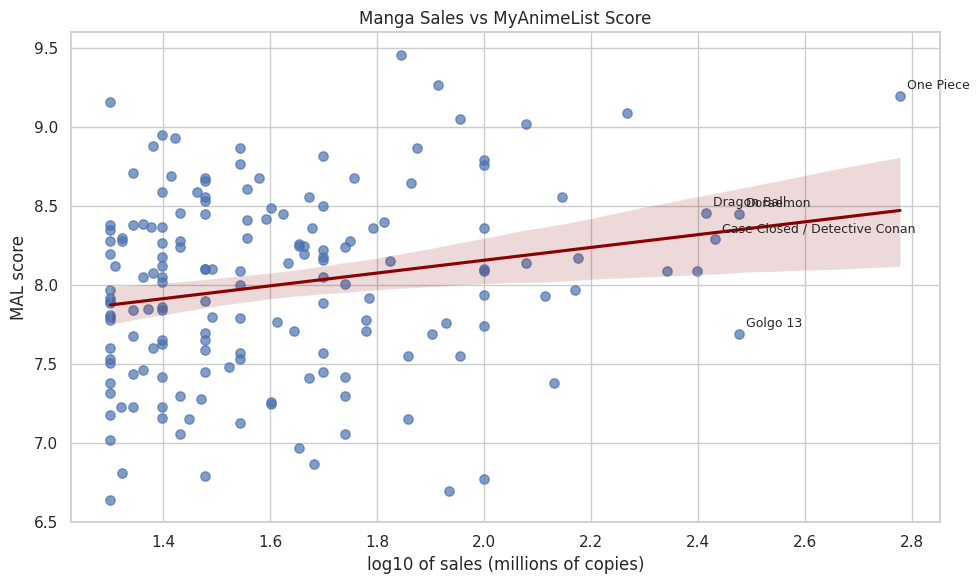

In [148]:
plt.figure(figsize=(10, 6))
sns.regplot(data=df_s, x="log_sales", y="score", scatter_kws={"alpha": 0.7, "s": 45}, line_kws={"color": "darkred"})
for _, r in df_s.nlargest(5, "sales_m").iterrows():
    plt.annotate(r["series"], (r["log_sales"], r["score"]), textcoords="offset points", xytext=(5, 5), fontsize=9)
plt.title("Manga Sales vs MyAnimeList Score")
plt.xlabel("log10 of sales (millions of copies)")
plt.ylabel("MAL score")
plt.tight_layout()
plt.show()

If the regression line is almost flat and the points form a cloud, the sales do not depend on the score: the best-sellers are rated well, but a higher score does not mean more copies sold. An upward slope would support H1.

### 2. Spearman correlation heatmap

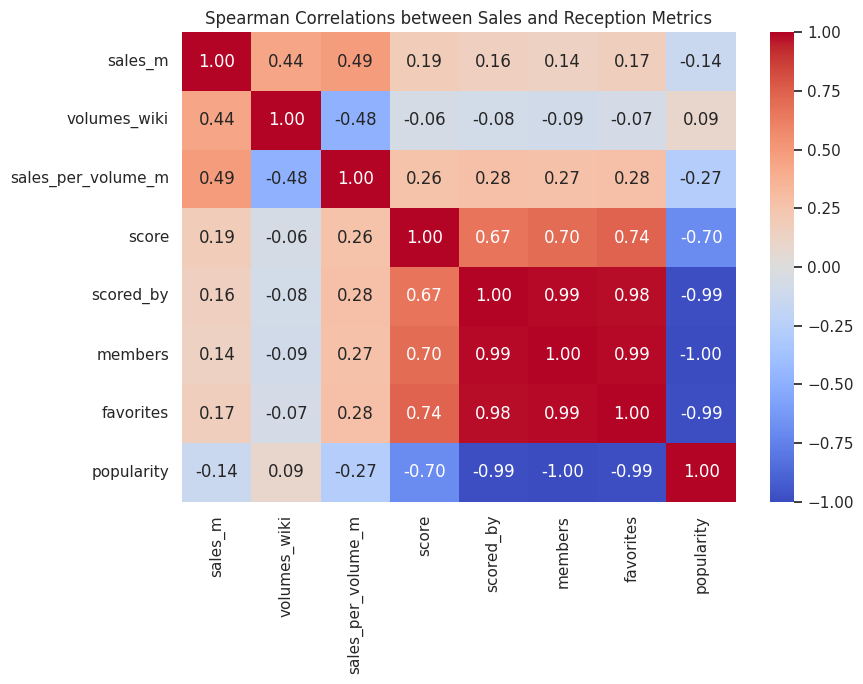

In [149]:
plt.figure(figsize=(9, 7))
sns.heatmap(corr_spearman, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1, fmt=".2f")
plt.title("Spearman Correlations between Sales and Reception Metrics")
plt.tight_layout()
plt.show()

The heatmap puts the whole correlation matrix in one picture. A block of strong correlations between `members`, `favorites` and `scored_by` is expected, since they all measure the size of the audience. What matters for H1 is the `sales_m` row and the `score` column.

### 3. Sales by publisher

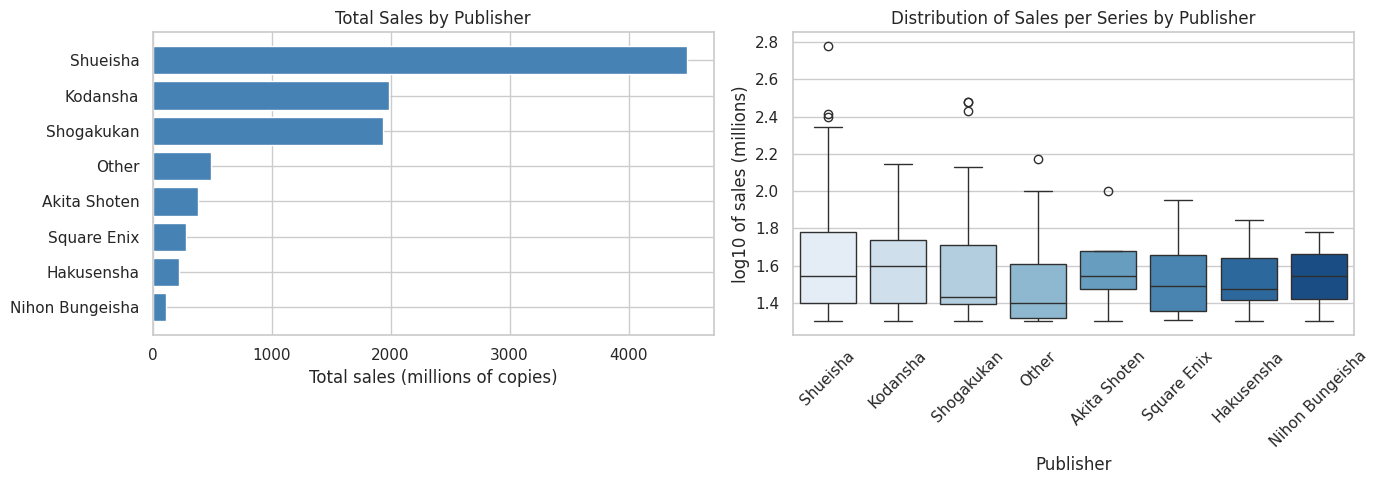

In [150]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

pub_plot = pub_summary.sort_values("total_sales")
axes[0].barh(pub_plot.index, pub_plot["total_sales"], color="steelblue")
axes[0].set_title("Total Sales by Publisher")
axes[0].set_xlabel("Total sales (millions of copies)")

sns.boxplot(data=df_m, x="publisher_grp", y="log_sales", order=pub_summary.index, ax=axes[1], palette="Blues")
axes[1].set_title("Distribution of Sales per Series by Publisher")
axes[1].set_xlabel("Publisher")
axes[1].set_ylabel("log10 of sales (millions)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

The bar chart shows the **total** sales (which also depends on the number of series), while the boxplot shows the distribution of sales **per series**.

### 4. Score by demographic

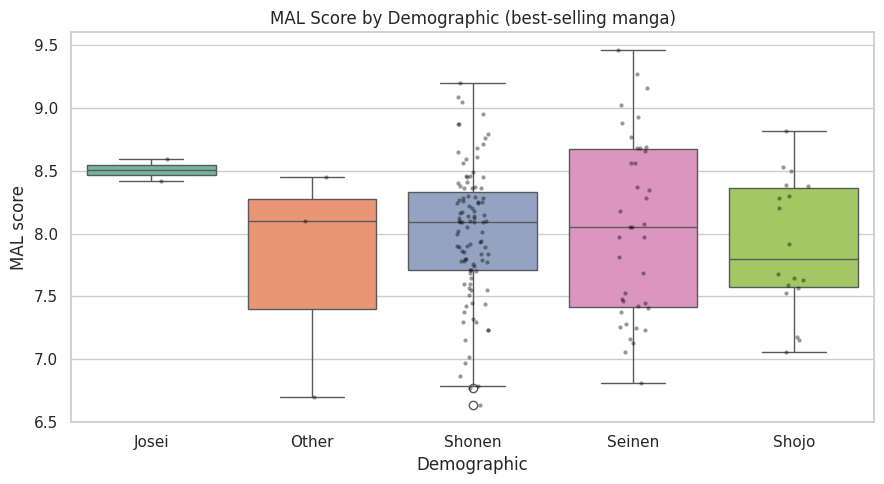

In [151]:
order = df_m.groupby("demographic")["score"].median().sort_values(ascending=False).index

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_m, x="demographic", y="score", order=order, palette="Set2")
sns.stripplot(data=df_m, x="demographic", y="score", order=order, color="black", alpha=0.4, size=3)
plt.title("MAL Score by Demographic (best-selling manga)")
plt.xlabel("Demographic")
plt.ylabel("MAL score")
plt.tight_layout()
plt.show()

Shonen is the most popular demogaphy, so naturally it has a wide spread of scores, while Josei, being the rarest one, has scores packed in a small ragne

### 5. Publisher x demographic heatmap

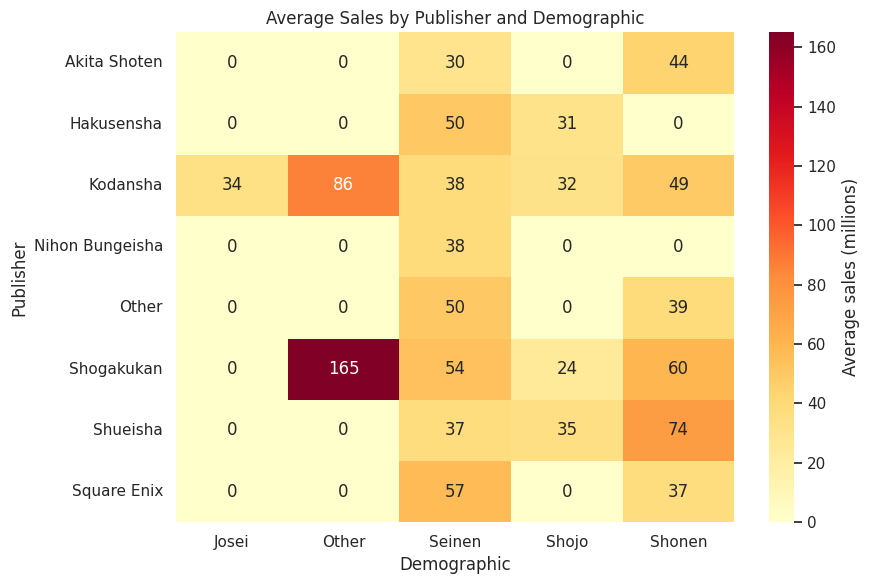

In [152]:
plt.figure(figsize=(9, 6))
sns.heatmap(pivot_sales, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "Average sales (millions)"})
plt.title("Average Sales by Publisher and Demographic")
plt.xlabel("Demographic")
plt.ylabel("Publisher")
plt.tight_layout()
plt.show()

This is the visual version of the pivot table. The empty (0) cells show the specialization of publishers, and the dark cells mark the most profitable combinations.

### 6. Genres: sales and reception

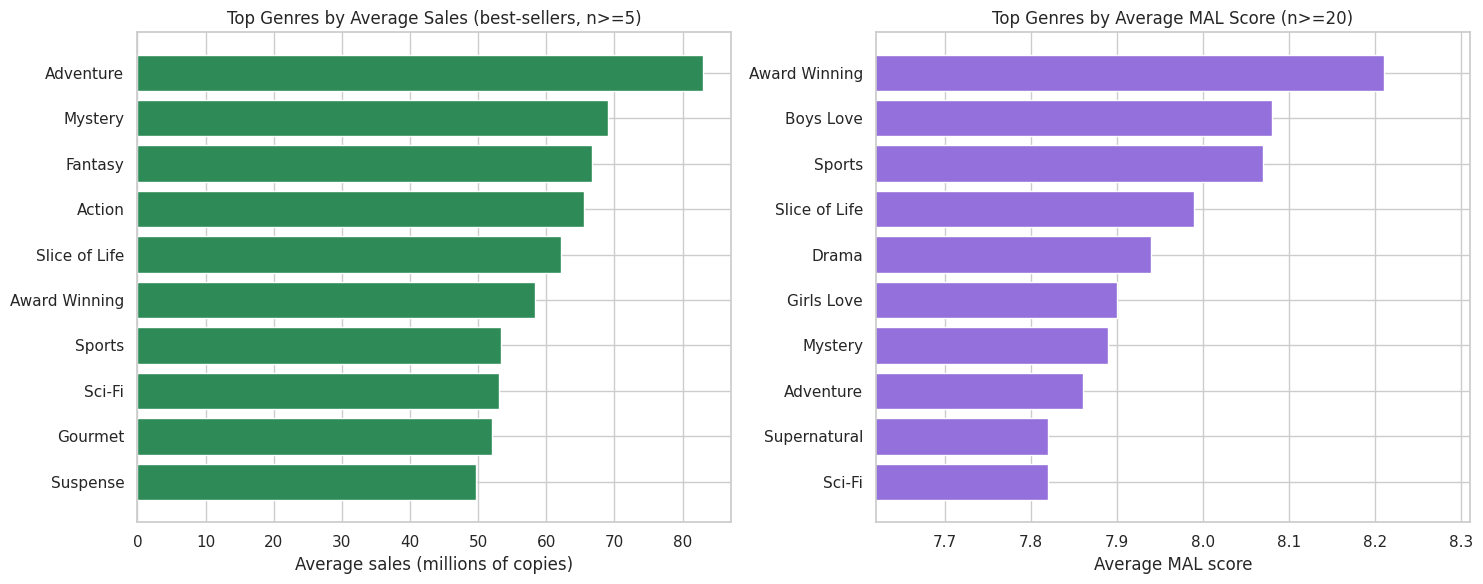

In [153]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

gs = genre_sales.head(10).sort_values("mean_sales")
axes[0].barh(gs.index, gs["mean_sales"], color="seagreen")
axes[0].set_title("Top Genres by Average Sales (best-sellers, n>=5)")
axes[0].set_xlabel("Average sales (millions of copies)")

ga = genre_api.head(10).sort_values("mean_score")
axes[1].barh(ga.index, ga["mean_score"], color="mediumpurple")
axes[1].set_xlim(ga["mean_score"].min() - 0.2, ga["mean_score"].max() + 0.1)
axes[1].set_title("Top Genres by Average MAL Score (n>=20)")
axes[1].set_xlabel("Average MAL score")

plt.tight_layout()
plt.show()

The left panel is about commerce and the right panel is about perception. If the two rankings contain different genres, a genre that readers rate highly is not the one that sells the most copies, which is another point against H1.

### 8. Score distribution: all popular manga vs best-sellers

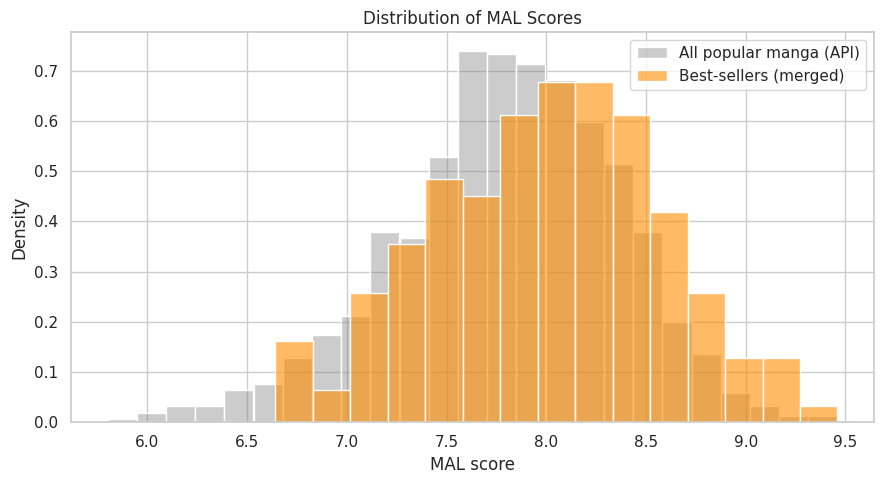

In [154]:
plt.figure(figsize=(9, 5))
sns.histplot(df_api["score"].dropna(), stat="density", bins=25, alpha=0.4, color="gray", label="All popular manga (API)")
sns.histplot(df_s["score"], stat="density", bins=15, alpha=0.6, color="darkorange", label="Best-sellers (merged)")
plt.title("Distribution of MAL Scores")
plt.xlabel("MAL score")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

If the orange (best-sellers) histogram is shifted to the right, best-selling manga are on average rated higher than the typical popular manga. This is a different question than the correlation *within* the best-sellers: it asks whether commercial success **in general** goes together with a higher rating.

## Task 10: Conclusions